Assignment 9 Solution

In [14]:
# all imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from matplotlib.colors import ListedColormap


1. Explore the data and create a common split. For each dataset, display a few rows, the class counts and a scatter plot coloured by class. Divide the observations once into 80% training and 20% test data using random_state=42 and stratification by class. Use the same split for every classifier on that dataset.


Dataset 1
          x         y  cluster
0  1.204876 -1.877549        3
1  0.190524  0.682476        2
2 -2.524391 -3.200064        1
3 -1.401345  0.713046        2
4 -0.527609  1.229975        2

Class counts:
cluster
1    375
2    375
3    375
4    375
Name: count, dtype: int64


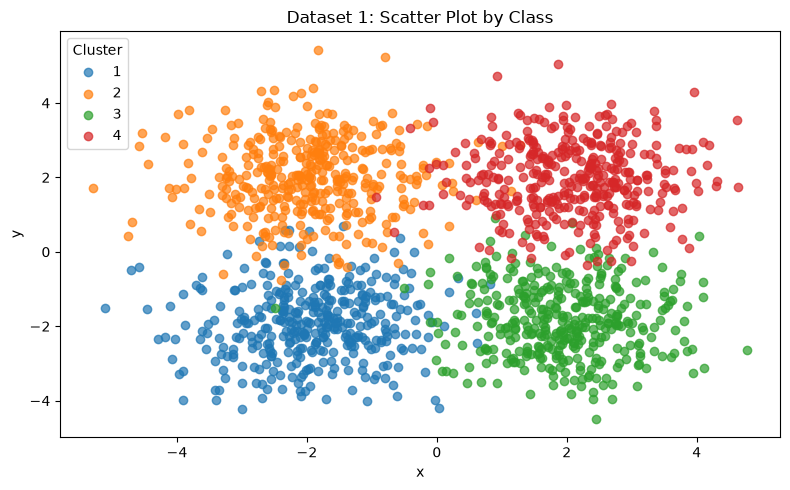


Dataset 2
          x         y  cluster
0 -2.911114 -0.214988        4
1 -1.513595 -0.187763        2
2  0.458368 -0.632647        1
3 -2.518231  0.165471        3
4 -0.414653 -1.429693        2

Class counts:
cluster
1    300
2    300
3    300
4    300
5    300
Name: count, dtype: int64


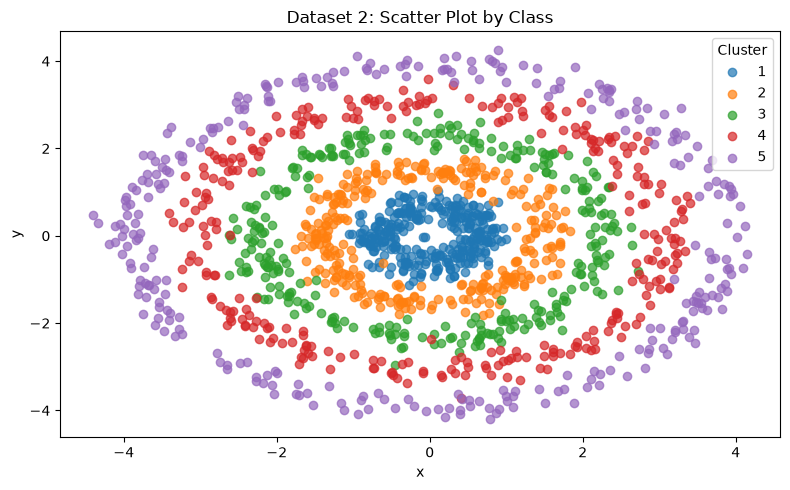


Dataset 3
          x         y  cluster
0  0.093224  1.074345        5
1  1.502937 -1.995782        2
2 -1.701505 -1.055810        1
3  0.667784 -1.919564        3
4 -0.262354 -1.924619        2

Class counts:
cluster
1    250
2    250
3    250
4    250
5    250
6    250
Name: count, dtype: int64


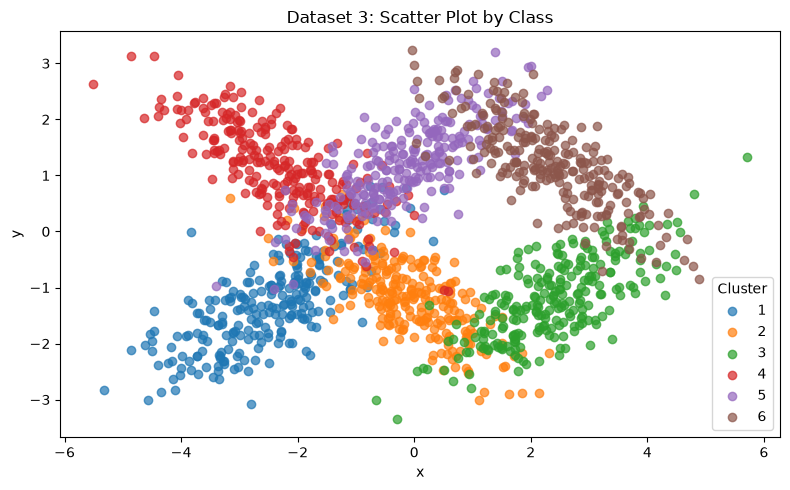

In [15]:
# Load datasets

data_1 = pd.read_csv("dataset_1.csv")
data_2 = pd.read_csv("dataset_2.csv")
data_3 = pd.read_csv("dataset_3.csv")

datas = [data_1, data_2, data_3]
split_data = []

# Explore data and create common splits

for i, data in enumerate(datas, start=1):

    print(f"\nDataset {i}")
    print(data.head())

    # Class counts
    print("\nClass counts:")
    print(data["cluster"].value_counts().sort_index())

    # Features and target
    X = data[["x", "y"]]
    y = data["cluster"]

    # Scatter plot coloured by class
    plt.figure(figsize=(8, 5))

    for label in sorted(y.unique()):
        mask = y == label
        plt.scatter(
            X.loc[mask, "x"],
            X.loc[mask, "y"],
            label=str(label),
            alpha=0.7
        )

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"Dataset {i}: Scatter Plot by Class")
    plt.legend(title="Cluster")
    plt.tight_layout()
    plt.show()

    # Stratified 80:20 split
    split_data.append(
        train_test_split(
            X, y,
            test_size=0.2,
            random_state=42,
            stratify=y
        )
    )


2. Fit the following classifiers using scikit-learn:

|Method|Settings|
|---|---|
|Logistic regression|Original features; degree-3 polynomial features (two models).|
|SVC|Linear kernel with C=0.5;RBF kernel with C=2 and gamma='scale'(two models).|
|Random forest|All combinations of min_samples_leaf ∈ {2,8} and max_depth ∈ {3,6}; 100 trees (four models). |
|k-nearest neighbours|k =1,5,11 (three models).|
|Neural network|MLPClassifier with hidden layers (2,), (6,), (6,3) and (3,6,3) (four models).|


Set probability=True for SVC. Use random_state=42 wherever supported, max_iter=2000 for
logistic regression and max_iter=1500 for neural networks. Retain other defaults. Fit the polynomial transformation on training data and reuse it for test data and the plotting grid; omit its
constant bias feature.
Explain the difference between the linear and RBF kernels, and list the features produced by the
degree-3 transformation.

In [16]:
# Define classifiers

algorithms = {
    # Logistic Regression
    "Logistic - Original": LogisticRegression(
        max_iter=2000, random_state=42
    ),

    "Logistic - Polynomial": make_pipeline(
        PolynomialFeatures(degree=3, include_bias=False),
        LogisticRegression(max_iter=2000, random_state=42)
    ),

    # Support Vector Classifier
    "SVC - Linear": SVC(
        kernel="linear", C=0.5,
        probability=True, random_state=42
    ),

    "SVC - RBF": SVC(
        kernel="rbf", C=2, gamma="scale",
        probability=True, random_state=42
    )
}

# Random Forest: 4 configurations
for leaf in [2, 8]:
    for depth in [3, 6]:
        algorithms[f"RF - leaf={leaf}, depth={depth}"] = (
            RandomForestClassifier(
                n_estimators=100,
                min_samples_leaf=leaf,
                max_depth=depth,
                random_state=42
            )
        )

# K-Nearest Neighbours: 3 configurations
for k in [1, 5, 11]:
    algorithms[f"KNN - k={k}"] = KNeighborsClassifier(
        n_neighbors=k
    )

# Neural Networks: 4 configurations
for layers in [(2,), (6,), (6, 3), (3, 6, 3)]:
    algorithms[f"MLP - {layers}"] = MLPClassifier(
        hidden_layer_sizes=layers,
        max_iter=1500,
        random_state=42
    )

print("\nTotal classifier configurations:", len(algorithms))

# Train all classifiers on each dataset

models = {}

for i, (X_train, X_test, y_train, y_test) in enumerate(
    split_data, start=1
):

    dataset_name = f"Dataset {i}"
    models[dataset_name] = {}

    print(f"\nTraining models for {dataset_name}")

    for name, algorithm in algorithms.items():

        model = clone(algorithm)
        model.fit(X_train, y_train)

        models[dataset_name][name] = model

        print(f"  Fitted: {name}")

print("\nTotal models trained:",
      sum(len(dataset_models) for dataset_models in models.values()))



Total classifier configurations: 15

Training models for Dataset 1
  Fitted: Logistic - Original
  Fitted: Logistic - Polynomial
  Fitted: SVC - Linear
  Fitted: SVC - RBF


c:\Users\parik\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\parik\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


  Fitted: RF - leaf=2, depth=3
  Fitted: RF - leaf=2, depth=6
  Fitted: RF - leaf=8, depth=3
  Fitted: RF - leaf=8, depth=6
  Fitted: KNN - k=1
  Fitted: KNN - k=5
  Fitted: KNN - k=11
  Fitted: MLP - (2,)
  Fitted: MLP - (6,)
  Fitted: MLP - (6, 3)
  Fitted: MLP - (3, 6, 3)

Training models for Dataset 2
  Fitted: Logistic - Original
  Fitted: Logistic - Polynomial


c:\Users\parik\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


  Fitted: SVC - Linear
  Fitted: SVC - RBF


c:\Users\parik\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


  Fitted: RF - leaf=2, depth=3
  Fitted: RF - leaf=2, depth=6
  Fitted: RF - leaf=8, depth=3
  Fitted: RF - leaf=8, depth=6
  Fitted: KNN - k=1
  Fitted: KNN - k=5
  Fitted: KNN - k=11
  Fitted: MLP - (2,)


c:\Users\parik\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1500) reached and the optimization hasn't converged yet.
  warnings.warn(


  Fitted: MLP - (6,)
  Fitted: MLP - (6, 3)
  Fitted: MLP - (3, 6, 3)

Training models for Dataset 3
  Fitted: Logistic - Original
  Fitted: Logistic - Polynomial
  Fitted: SVC - Linear


c:\Users\parik\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\parik\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


  Fitted: SVC - RBF
  Fitted: RF - leaf=2, depth=3
  Fitted: RF - leaf=2, depth=6
  Fitted: RF - leaf=8, depth=3
  Fitted: RF - leaf=8, depth=6
  Fitted: KNN - k=1
  Fitted: KNN - k=5
  Fitted: KNN - k=11
  Fitted: MLP - (2,)
  Fitted: MLP - (6,)
  Fitted: MLP - (6, 3)
  Fitted: MLP - (3, 6, 3)

Total models trained: 45


Linear: the linear SVC is used for data where the data can be classified on the basis of a straight line or space.

RBF: The RBF SVC is used for data which can't be classified with a linear classification.

Degree-3 transformation: It creates features so that it can learn the non-linear attributes needed for classification. In our case we have x,y which will be converted into 1, x, y, x^2, xy, y^2, x^3, x^2y, xy^2, y^3.

3. Record the metrics for train and test data. For every model and dataset, calculate:
- Accuracy
- Precision, recall and F1-score for each class and their macro averages.
- One-versus-rest AUC for each class and its macro average.

Save the results in one CSV with dataset, model and split identifiers: 3 × 15 × 2 = 90 rows. Align
probability columns with the model’s class labels. Leave metric columns for absent classes empty;
use zero_division=0 for undefined precision, recall or F1. A macro average assigns equal weight
to each class.

In [ ]:

# Calculate metrics and save to CSV

results = []

for i, (X_train, X_test, y_train, y_test) in enumerate(
    split_data, start=1
):
    dataset_name = f"Dataset {i}"

    # Get all class labels present in this dataset
    all_classes = np.sort(
        pd.concat([
            y_train.reset_index(drop=True),
            y_test.reset_index(drop=True)
        ]).unique()
    )

    # Evaluate both training and test splits
    for split_name, X_split, y_split in [
        ("train", X_train, y_train),
        ("test", X_test, y_test)
    ]:

        for model_name, model in models[dataset_name].items():

            # Predictions and probabilities
            y_pred = model.predict(X_split)
            y_prob = model.predict_proba(X_split)

            # Classes in the order used by predict_proba
            model_classes = model.classes_

            # Basic metrics
            row = {
                "dataset": dataset_name,
                "model": model_name,
                "split": split_name,
                "accuracy": accuracy_score(y_split, y_pred)
            }

            # Calculate per-class precision, recall and F1
            precision, recall, f1, _ = (
                precision_recall_fscore_support(
                    y_split,
                    y_pred,
                    labels=all_classes,
                    zero_division=0
                )
            )

            # Store all precision values first
            for j, label in enumerate(all_classes):
                row[f"precision_class_{label}"] = (
                    precision[j]
                )

            # Store all recall values
            for j, label in enumerate(all_classes):
                row[f"recall_class_{label}"] = (
                    recall[j]
                )

            # Store all F1 values
            for j, label in enumerate(all_classes):
                row[f"f1_class_{label}"] = (
                    f1[j]
                )

            # Align predicted probabilities with all_classes
            aligned_prob = np.zeros(
                (len(y_split), len(all_classes))
            )

            for j, label in enumerate(model_classes):
                position = np.where(all_classes == label)[0][0]
                aligned_prob[:, position] = y_prob[:, j]

            # One-vs-rest AUC for each class
            y_binary = label_binarize(
                y_split,
                classes=all_classes
            )

            auc_values = []

            for j, label in enumerate(all_classes):

                # AUC requires both positive and negative samples
                if (
                    np.any(y_split == label)
                    and np.any(y_split != label)
                ):
                    class_auc = roc_auc_score(
                        y_binary[:, j],
                        aligned_prob[:, j]
                    )

                    row[f"auc_class_{label}"] = class_auc
                    auc_values.append(class_auc)

                else:
                    row[f"auc_class_{label}"] = np.nan

            # Macro metrics: average across all classes
            # Macro precision, recall and F1
            row["precision_macro"] = np.mean(precision)
            row["recall_macro"] = np.mean(recall)
            row["f1_macro"] = np.mean(f1)

            # Macro AUC
            row["auc_macro"] = (
                np.mean(auc_values)
                if auc_values else np.nan
            )

            results.append(row)


# Create DataFrame
results_df = pd.DataFrame(results)

# Explicitly arrange columns in the desired order
metadata_columns = [
    "dataset",
    "model",
    "split",
    "accuracy"
]

precision_columns = [
    f"precision_class_{label}"
    for label in all_classes
]

recall_columns = [
    f"recall_class_{label}"
    for label in all_classes
]

f1_columns = [
    f"f1_class_{label}"
    for label in all_classes
]

auc_columns = [
    f"auc_class_{label}"
    for label in all_classes
]

macro_columns = [
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "auc_macro"
]

column_order = (
    metadata_columns
    + precision_columns
    + recall_columns
    + f1_columns
    + auc_columns
    + macro_columns
)

results_df = results_df[column_order]

# Save all metrics to CSV
results_df.to_csv(
    "parikshith_r_nayak_assignment_9_results.csv",
    index=False
)

print("Saved parikshith_r_nayak_assignment_9_results.csv")
print("Total rows:", len(results_df))
print("Total columns:", len(results_df.columns))
print(results_df.head())


Saved parikshith_r_nayak_9_results.csv
Total rows: 90
Total columns: 32
     dataset                  model  split  accuracy  precision_class_1  \
0  Dataset 1    Logistic - Original  train  0.952500           0.947541   
1  Dataset 1  Logistic - Polynomial  train  0.952500           0.947368   
2  Dataset 1           SVC - Linear  train  0.949167           0.941368   
3  Dataset 1              SVC - RBF  train  0.950833           0.944444   
4  Dataset 1   RF - leaf=2, depth=3  train  0.957500           0.956667   

   precision_class_2  precision_class_3  precision_class_4  precision_class_5  \
0           0.949664           0.959866           0.953020                NaN   
1           0.953177           0.959459           0.950166                NaN   
2           0.946667           0.956229           0.952703                NaN   
3           0.949833           0.959459           0.949833                NaN   
4           0.969072           0.956954           0.947883              

4. Plot the model outputs. For every model on every dataset, draw:
- A decision-boundary plot, with test observations coloured by their true classes.
- One-versus-rest micro ROC curves for train and test data, with a diagonal reference and the
corresponding micro AUCs. Pool the binary class indicators and probability scores to obtain
these curves.

Label each plot with the dataset and model. The micro AUC shown in a ROC plot is distinct from
the macro AUC recorded in the metric table.

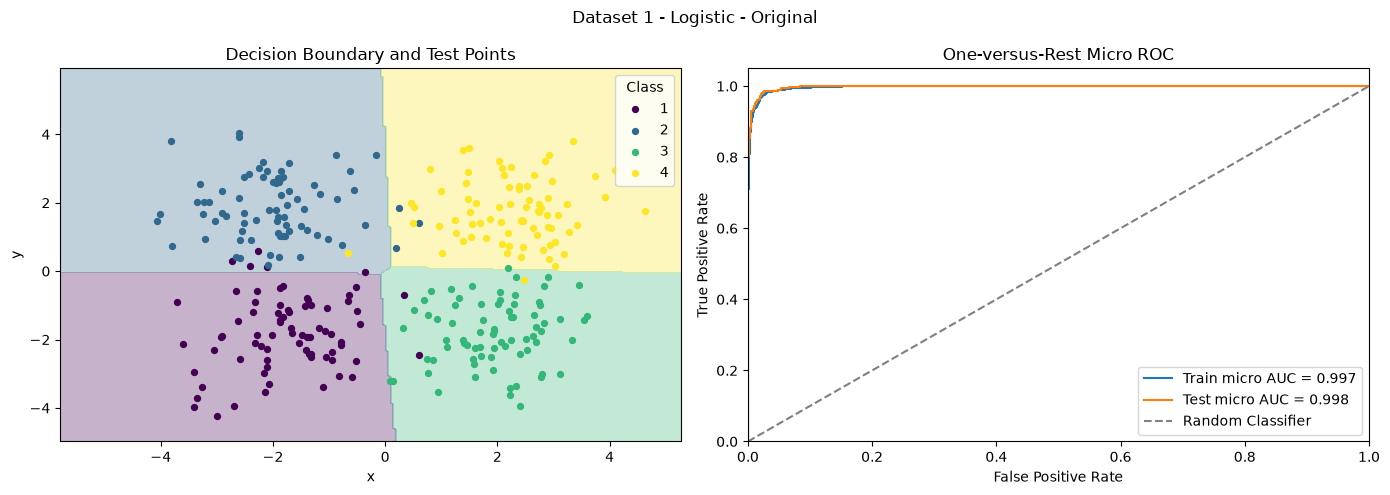

Dataset 1 | Logistic - Original | Train Micro AUC: 0.9967 | Test Micro AUC: 0.9979


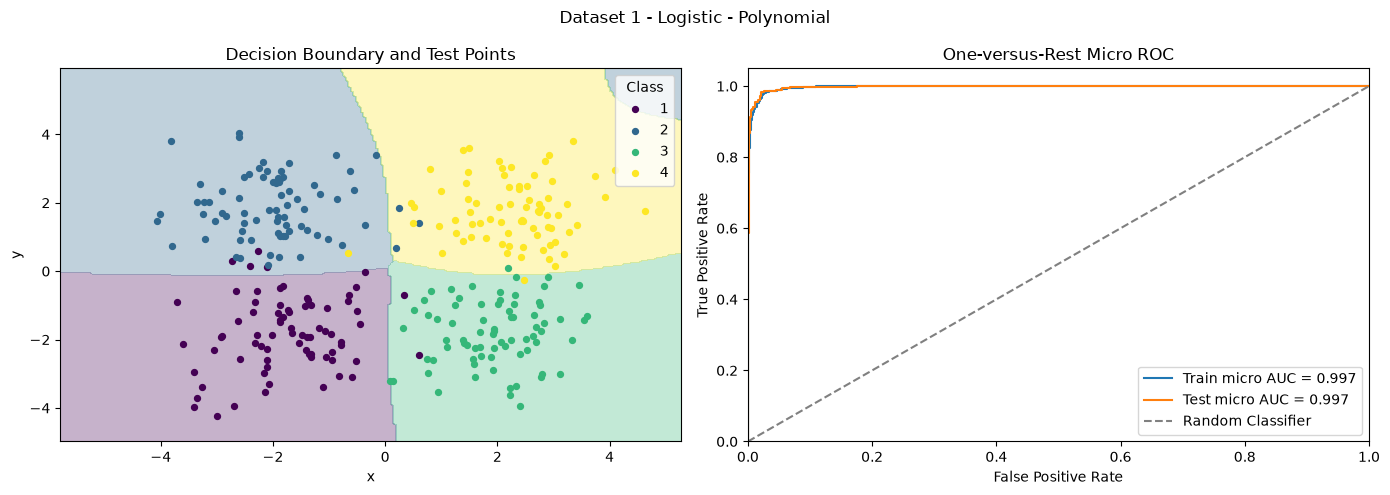

Dataset 1 | Logistic - Polynomial | Train Micro AUC: 0.9972 | Test Micro AUC: 0.9974


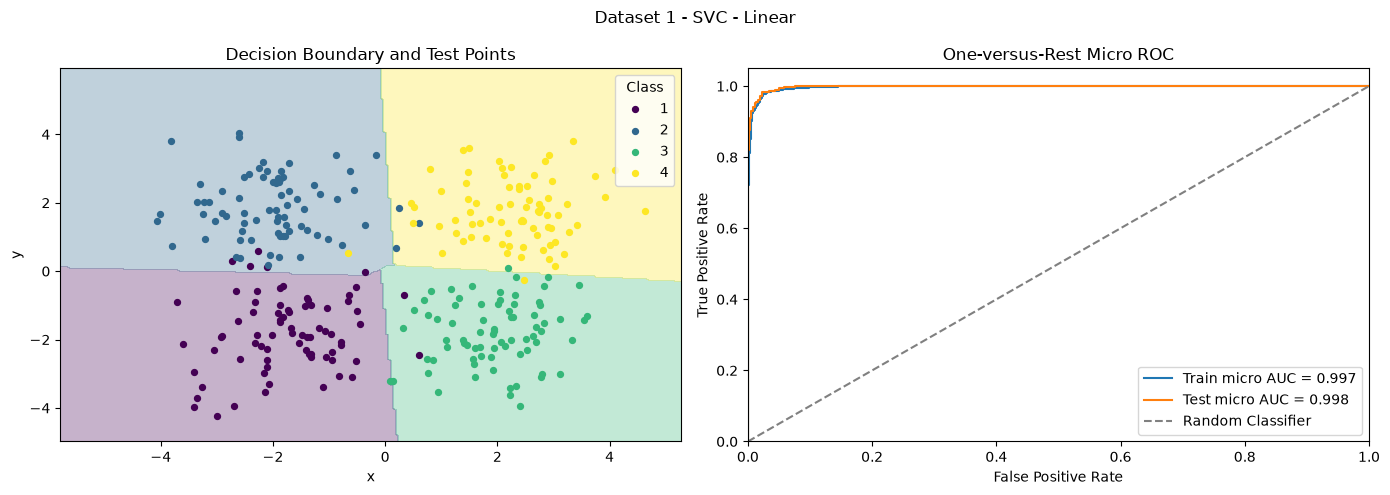

Dataset 1 | SVC - Linear | Train Micro AUC: 0.9967 | Test Micro AUC: 0.9980


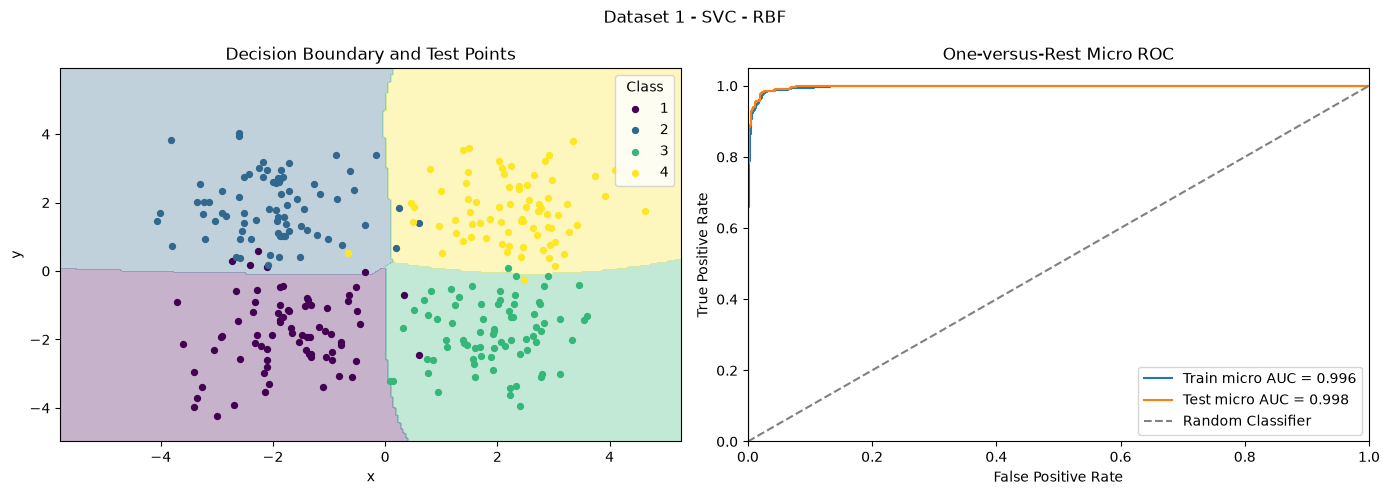

Dataset 1 | SVC - RBF | Train Micro AUC: 0.9965 | Test Micro AUC: 0.9978


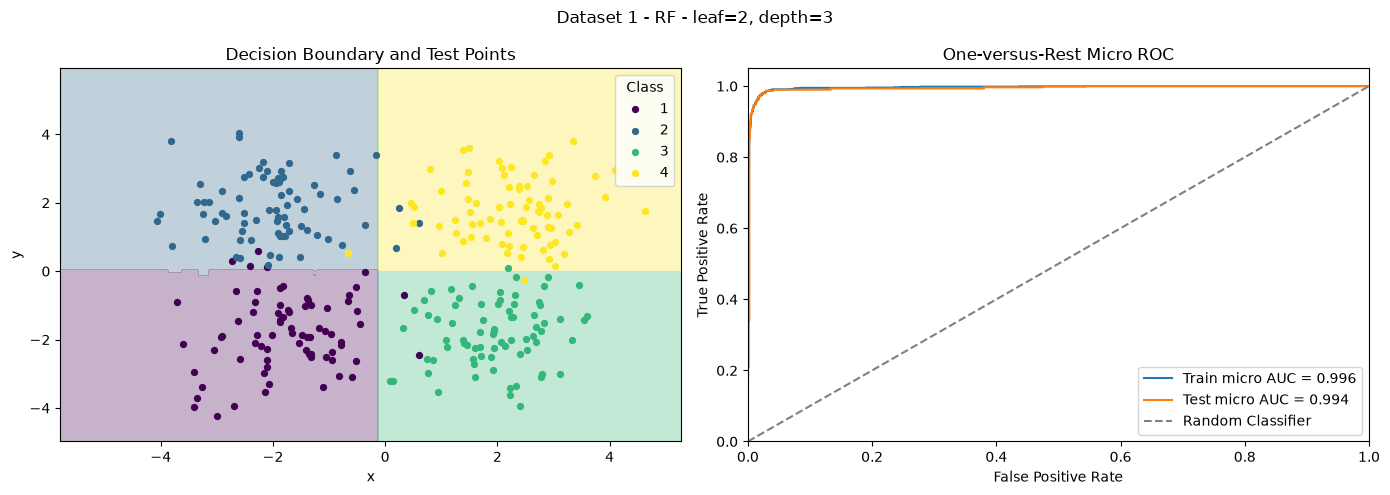

Dataset 1 | RF - leaf=2, depth=3 | Train Micro AUC: 0.9961 | Test Micro AUC: 0.9941


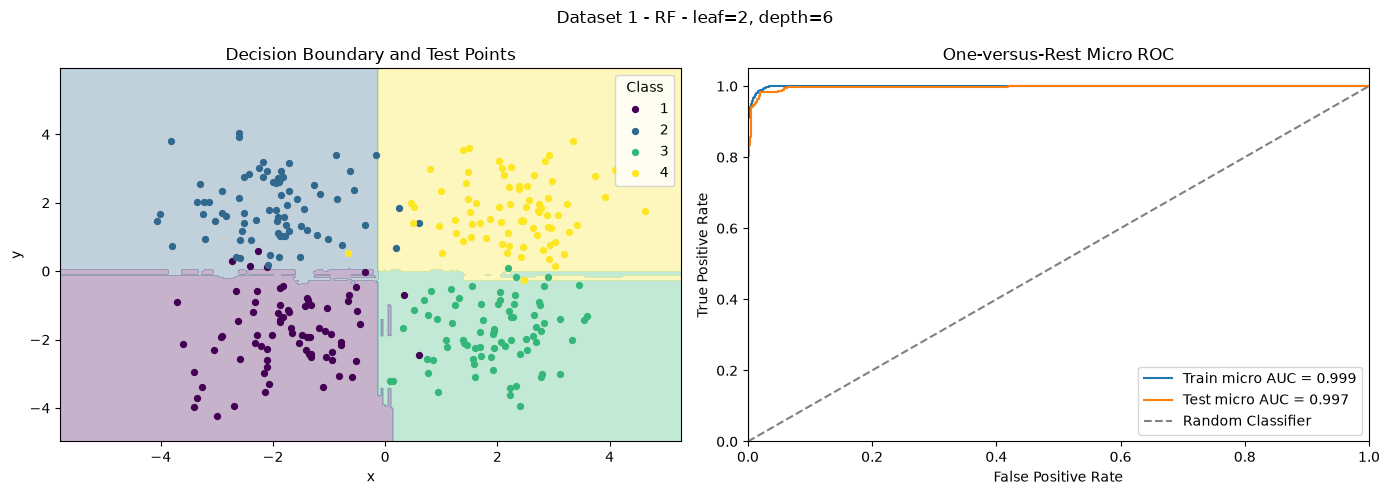

Dataset 1 | RF - leaf=2, depth=6 | Train Micro AUC: 0.9991 | Test Micro AUC: 0.9967


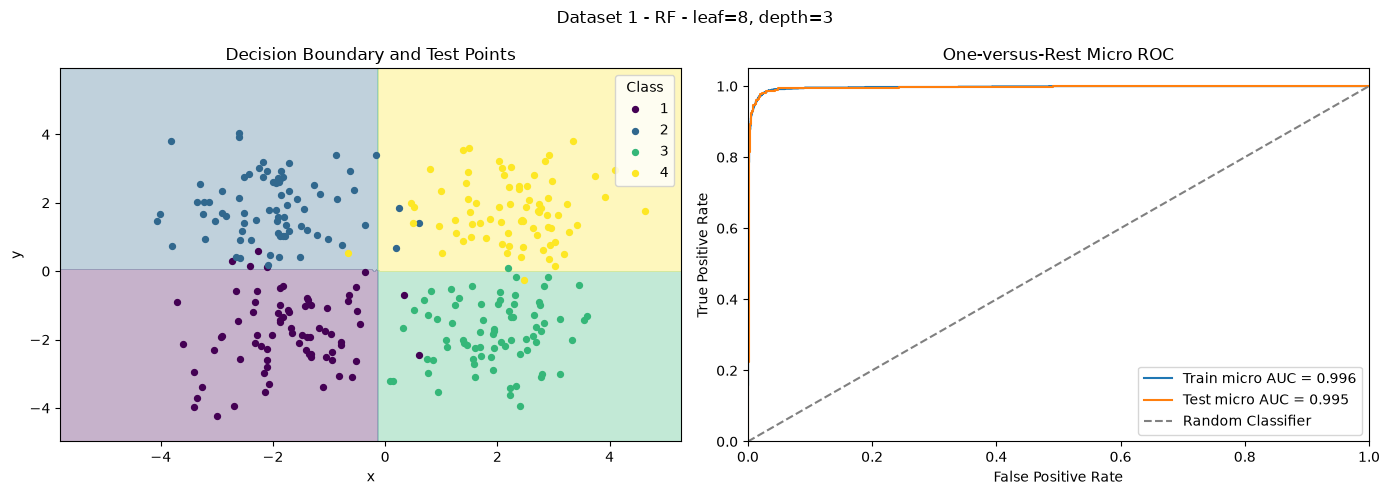

Dataset 1 | RF - leaf=8, depth=3 | Train Micro AUC: 0.9964 | Test Micro AUC: 0.9949


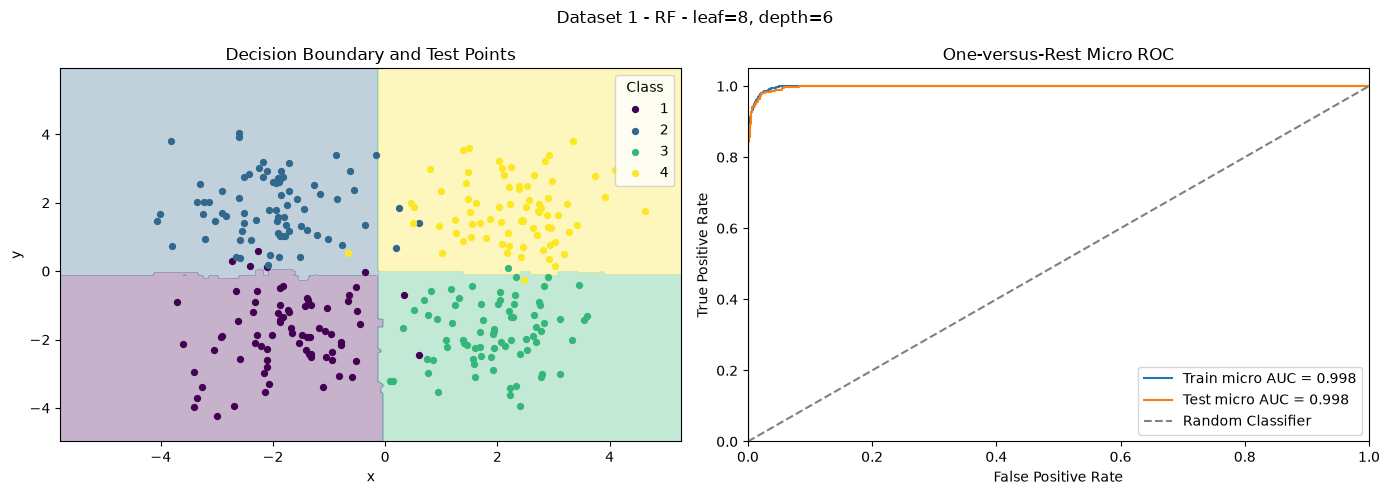

Dataset 1 | RF - leaf=8, depth=6 | Train Micro AUC: 0.9984 | Test Micro AUC: 0.9979


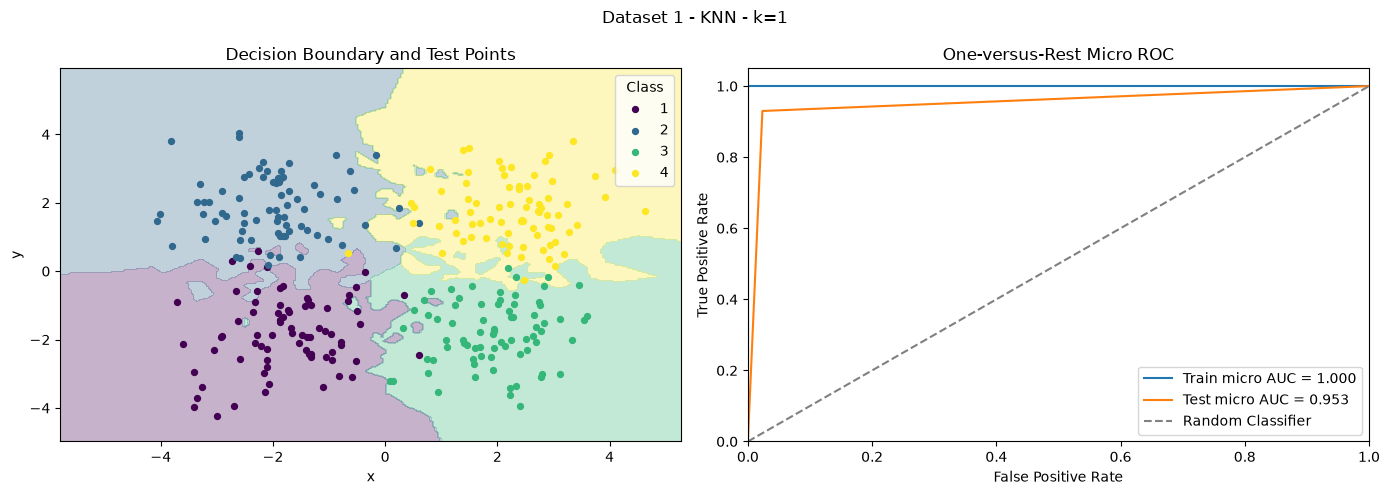

Dataset 1 | KNN - k=1 | Train Micro AUC: 1.0000 | Test Micro AUC: 0.9533


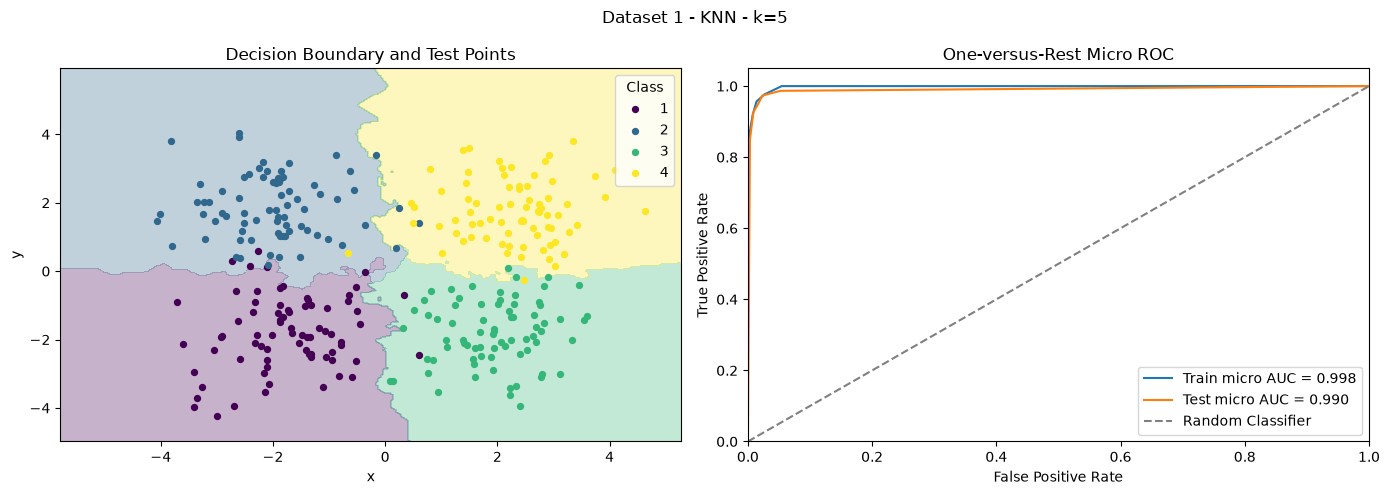

Dataset 1 | KNN - k=5 | Train Micro AUC: 0.9979 | Test Micro AUC: 0.9898


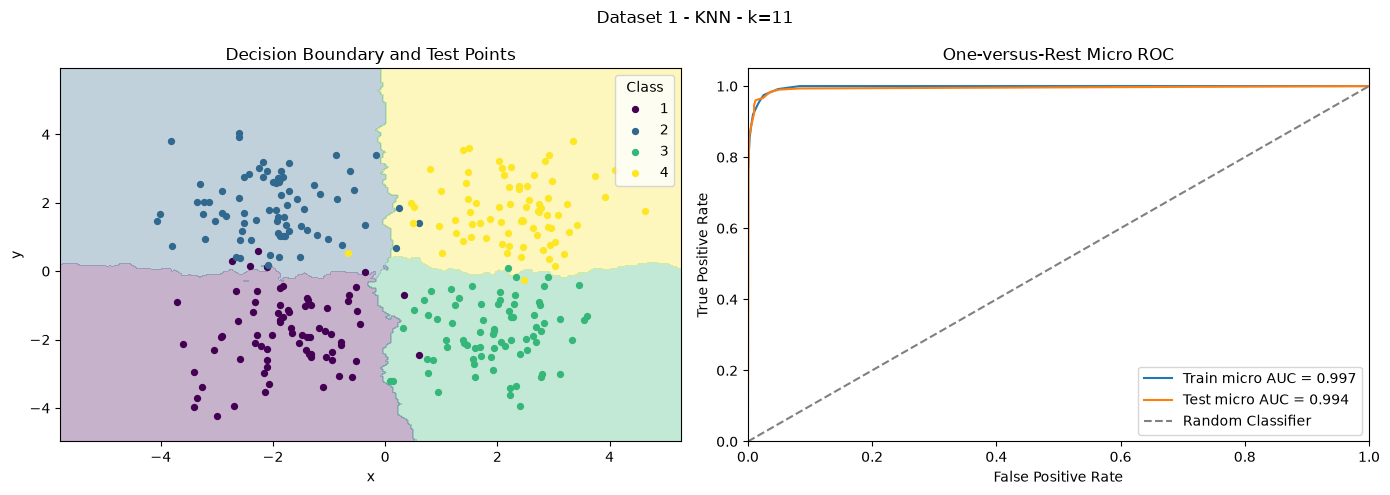

Dataset 1 | KNN - k=11 | Train Micro AUC: 0.9975 | Test Micro AUC: 0.9939


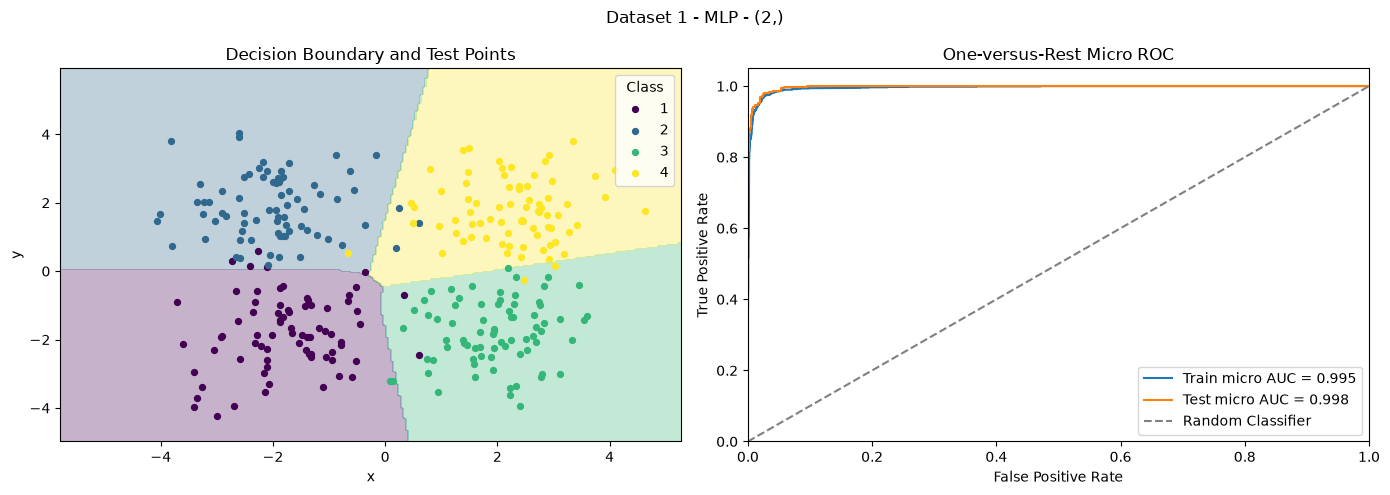

Dataset 1 | MLP - (2,) | Train Micro AUC: 0.9954 | Test Micro AUC: 0.9977


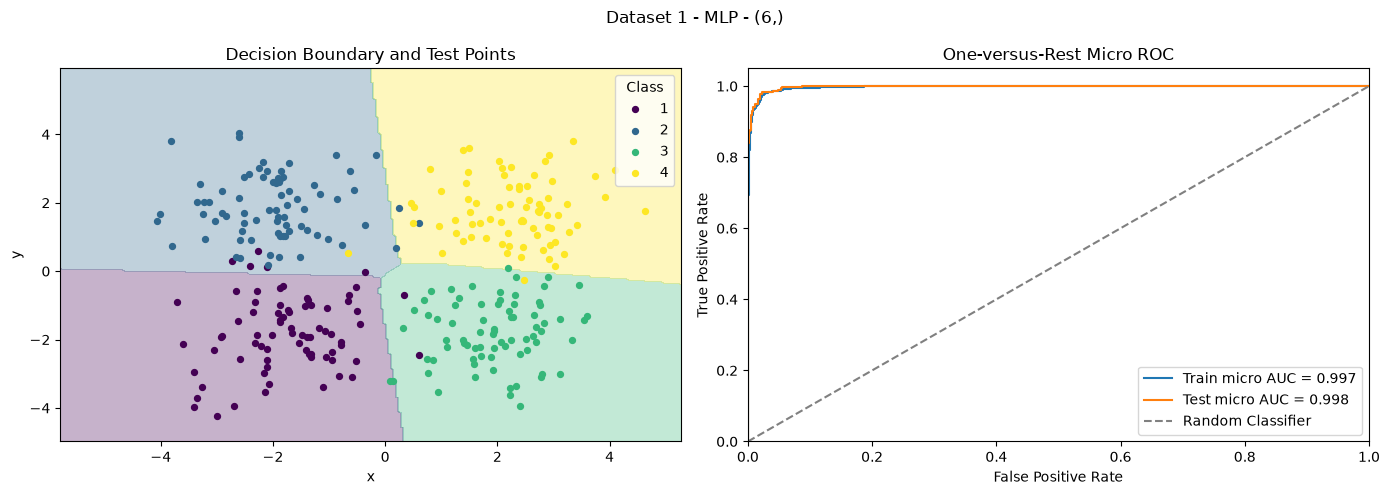

Dataset 1 | MLP - (6,) | Train Micro AUC: 0.9965 | Test Micro AUC: 0.9979


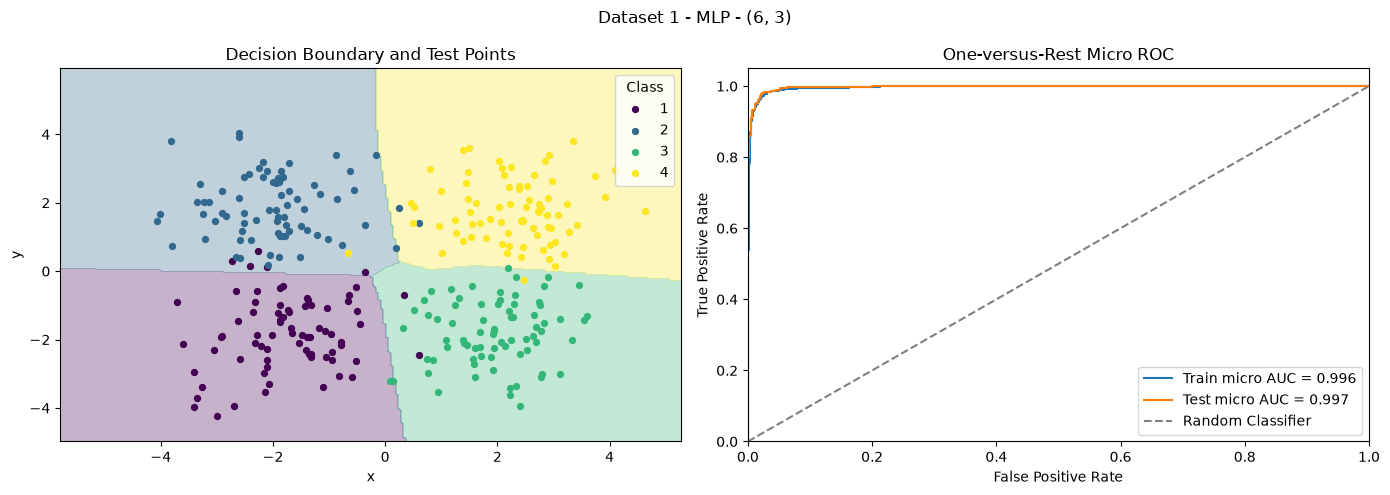

Dataset 1 | MLP - (6, 3) | Train Micro AUC: 0.9958 | Test Micro AUC: 0.9974


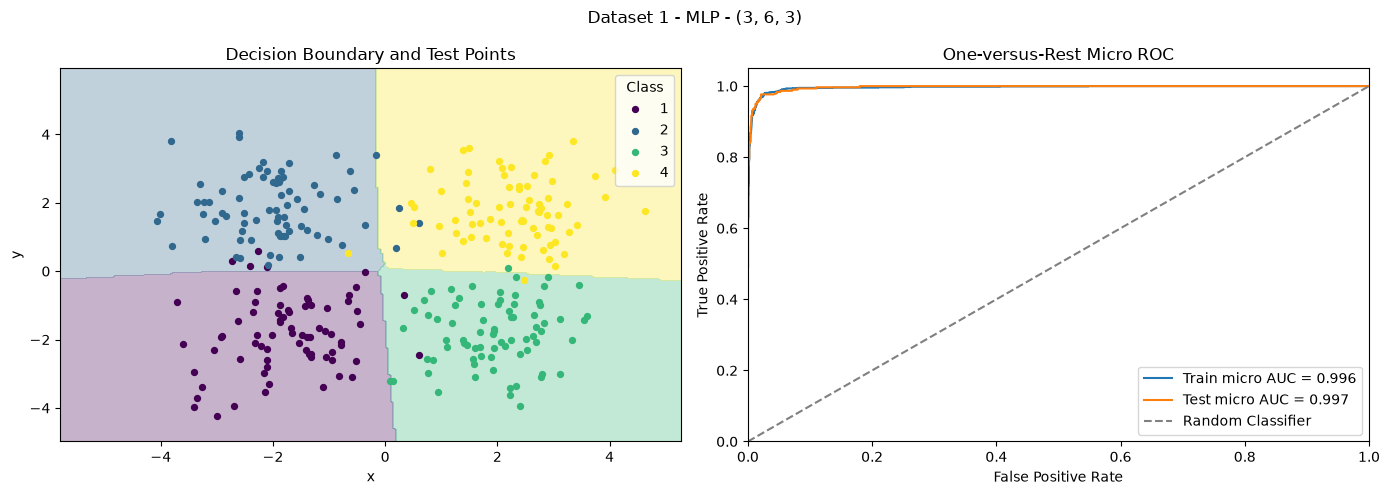

Dataset 1 | MLP - (3, 6, 3) | Train Micro AUC: 0.9960 | Test Micro AUC: 0.9968


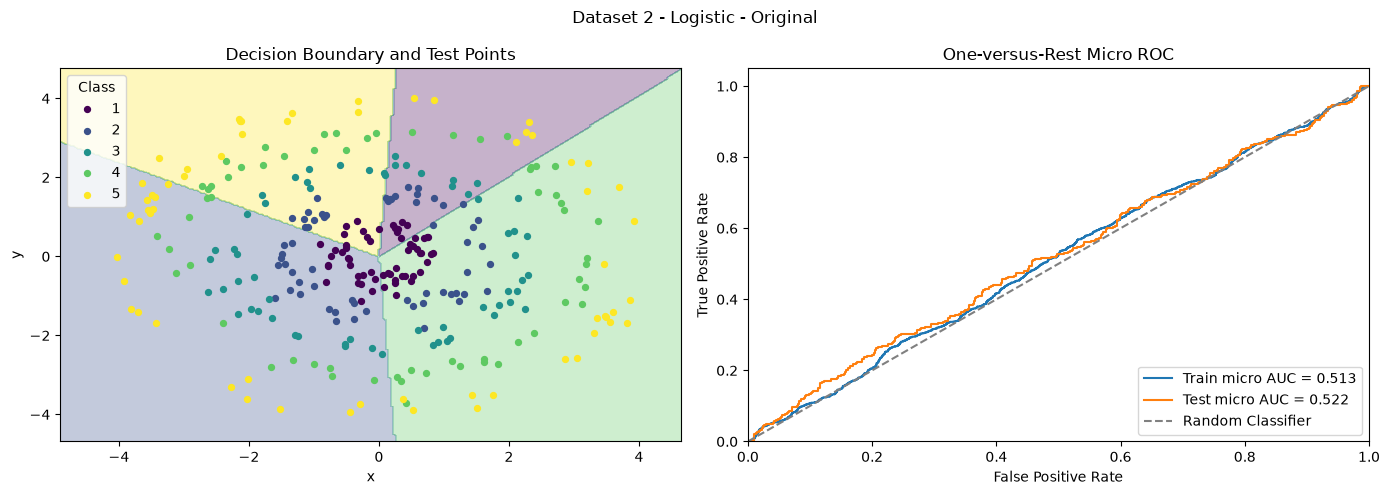

Dataset 2 | Logistic - Original | Train Micro AUC: 0.5134 | Test Micro AUC: 0.5216


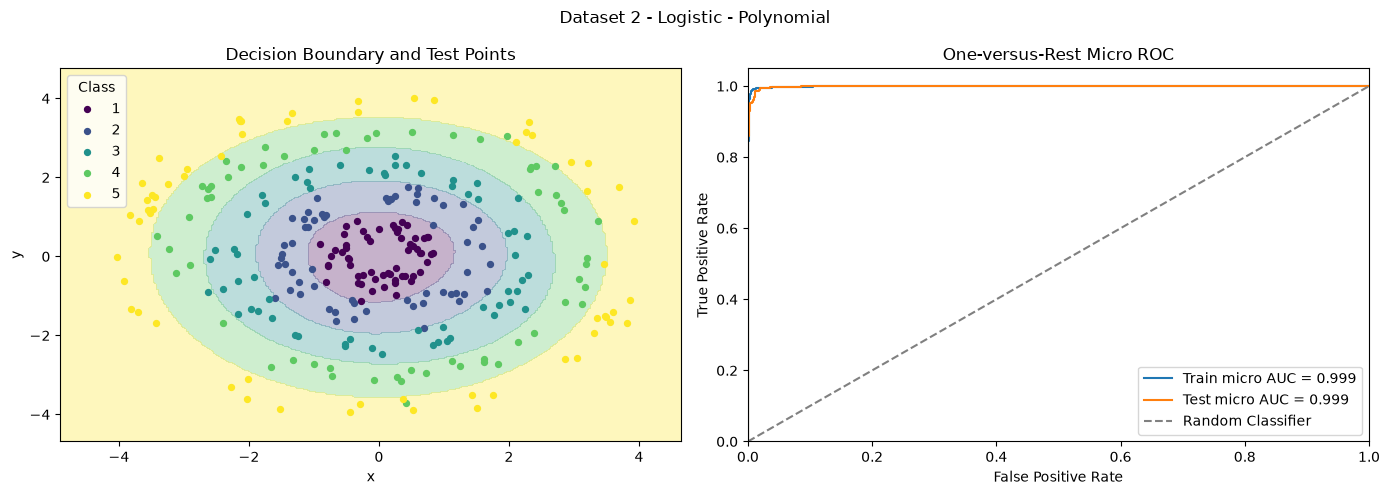

Dataset 2 | Logistic - Polynomial | Train Micro AUC: 0.9992 | Test Micro AUC: 0.9988


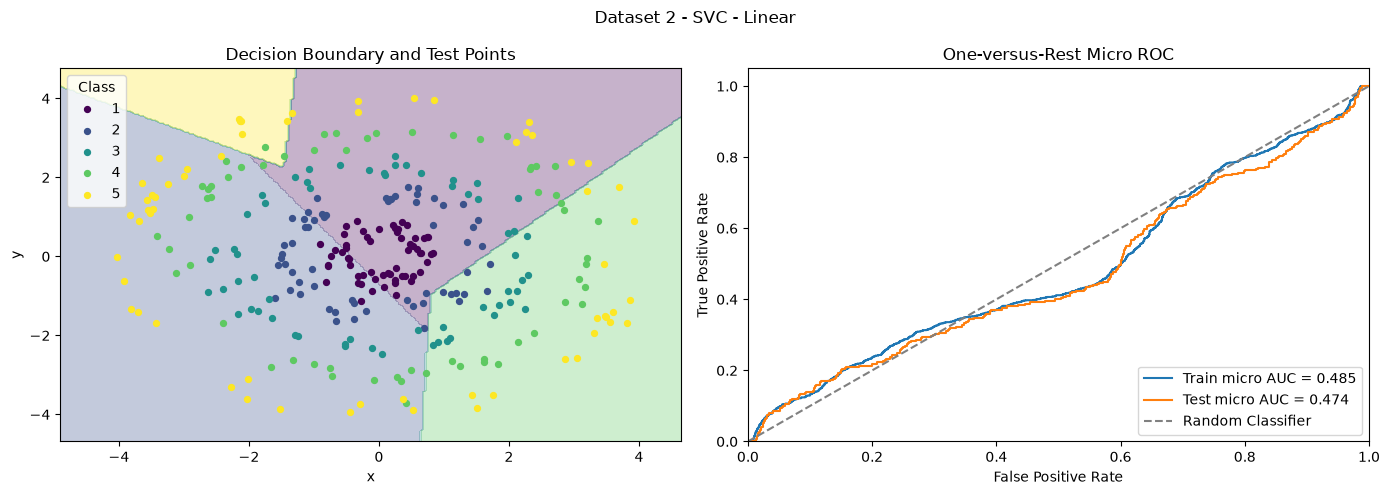

Dataset 2 | SVC - Linear | Train Micro AUC: 0.4846 | Test Micro AUC: 0.4742


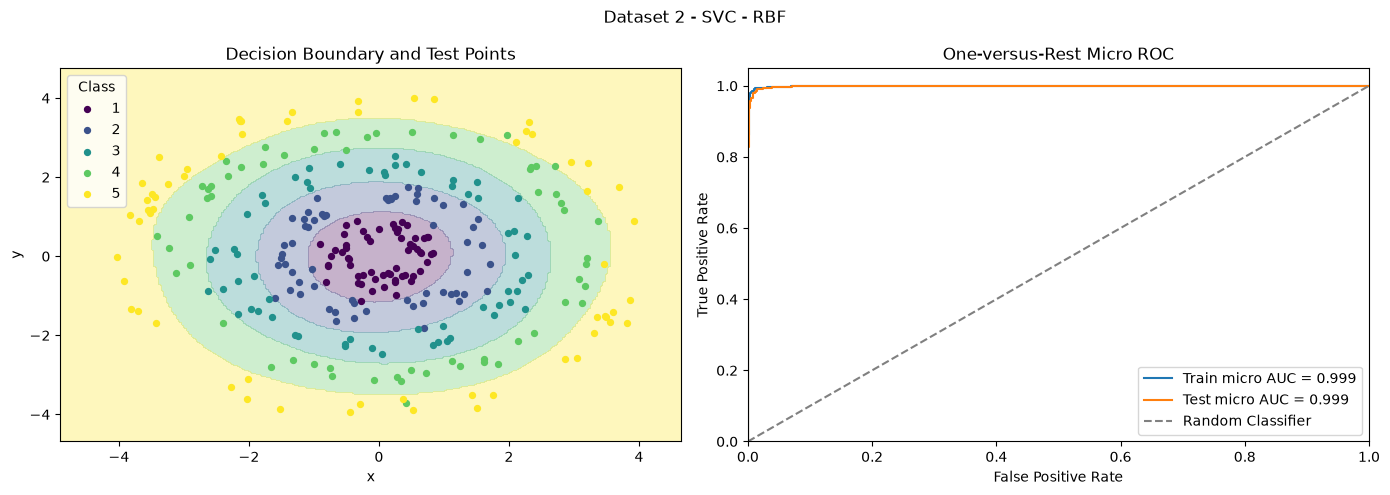

Dataset 2 | SVC - RBF | Train Micro AUC: 0.9991 | Test Micro AUC: 0.9989


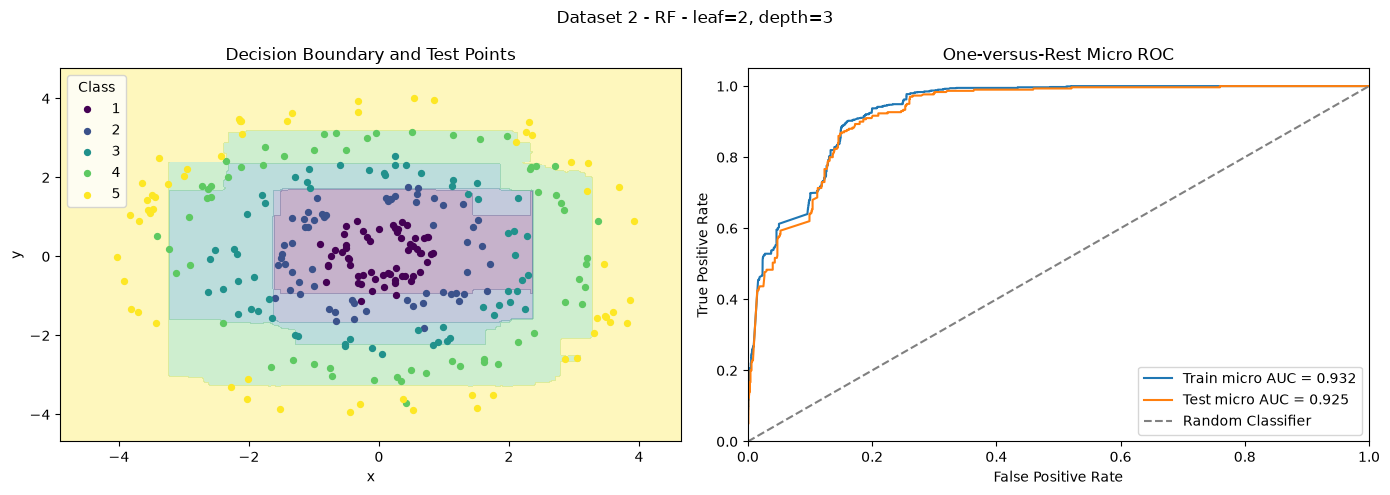

Dataset 2 | RF - leaf=2, depth=3 | Train Micro AUC: 0.9325 | Test Micro AUC: 0.9246


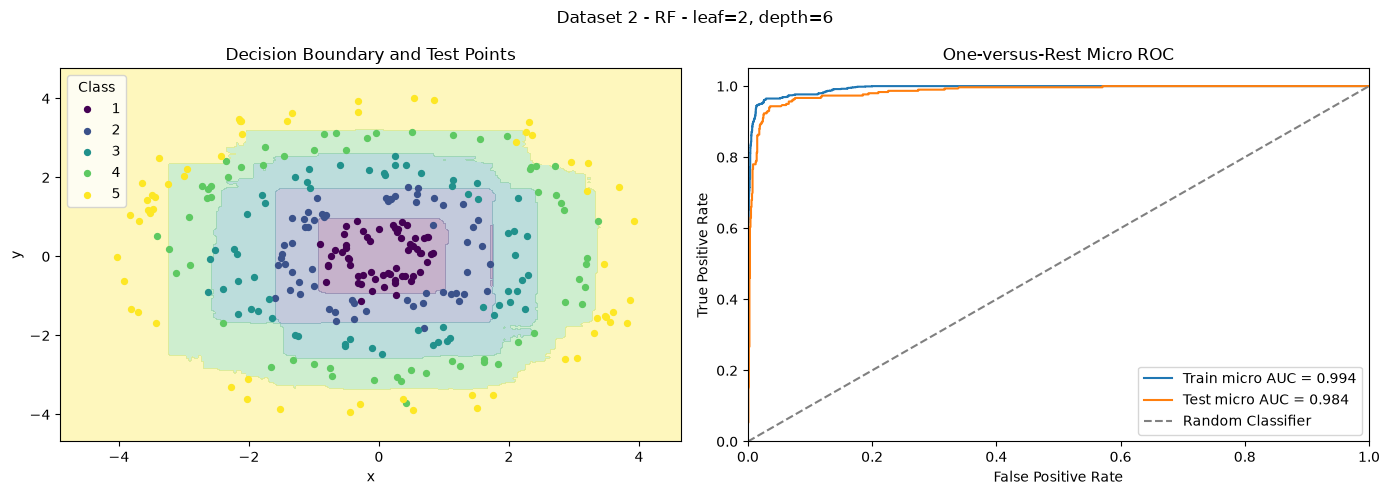

Dataset 2 | RF - leaf=2, depth=6 | Train Micro AUC: 0.9939 | Test Micro AUC: 0.9844


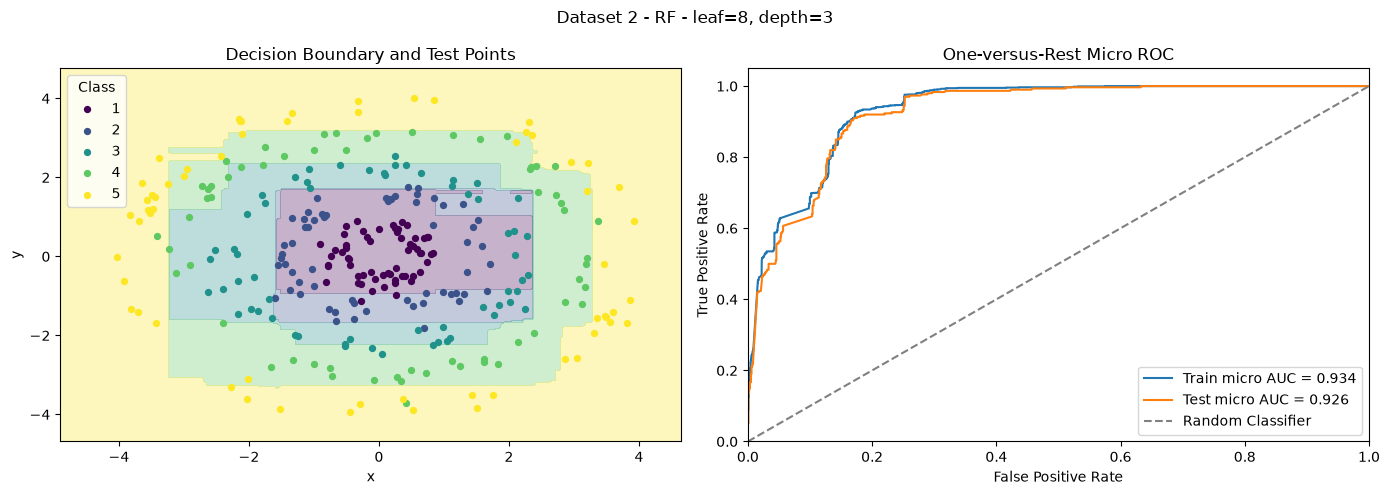

Dataset 2 | RF - leaf=8, depth=3 | Train Micro AUC: 0.9335 | Test Micro AUC: 0.9261


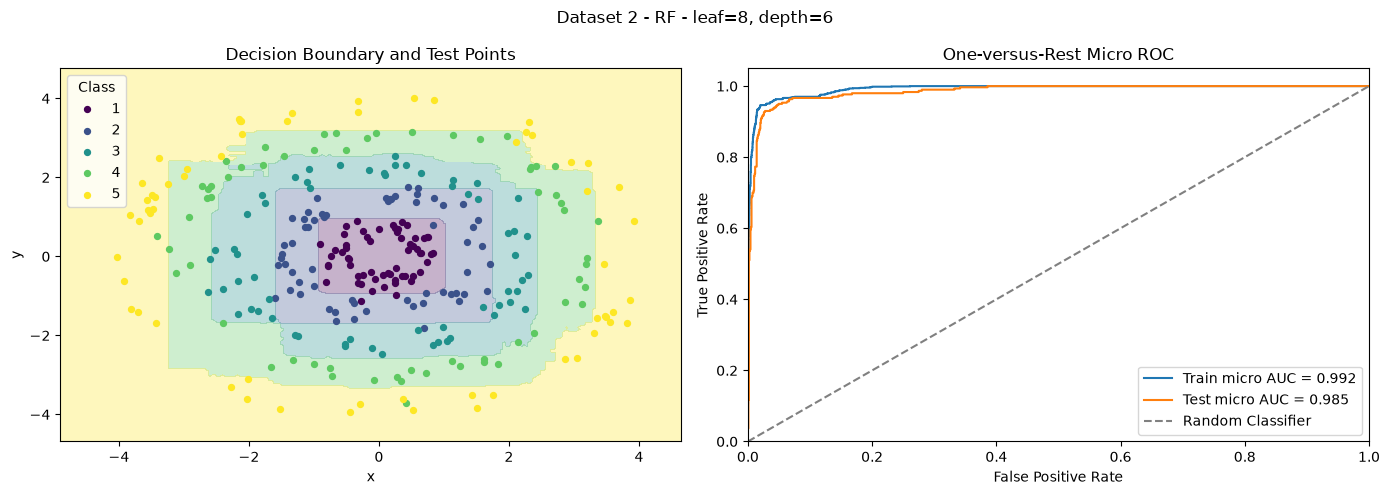

Dataset 2 | RF - leaf=8, depth=6 | Train Micro AUC: 0.9918 | Test Micro AUC: 0.9847


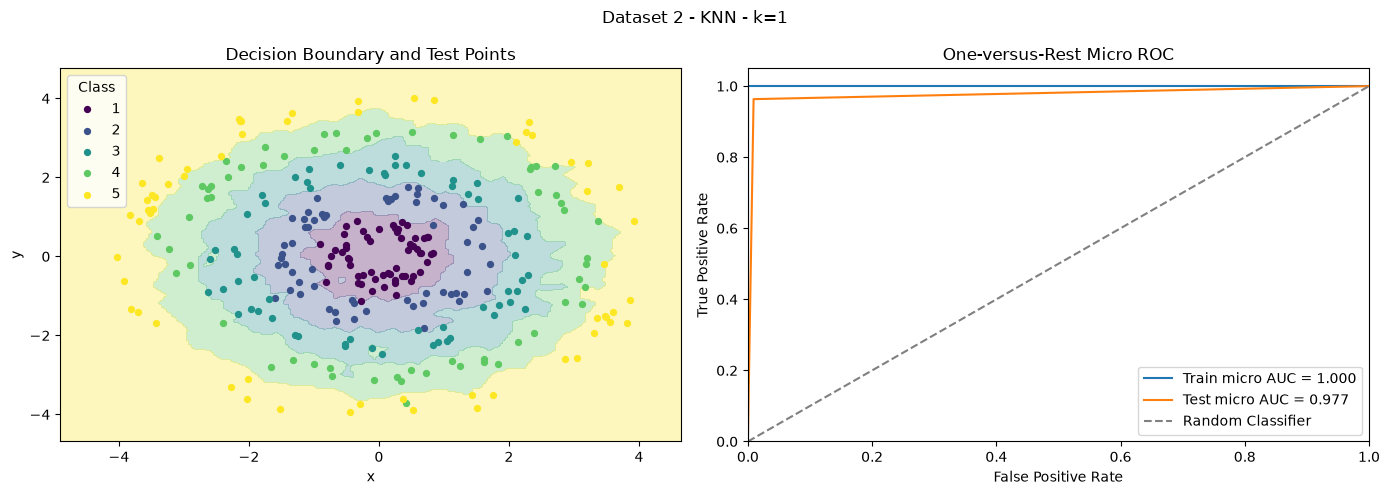

Dataset 2 | KNN - k=1 | Train Micro AUC: 1.0000 | Test Micro AUC: 0.9771


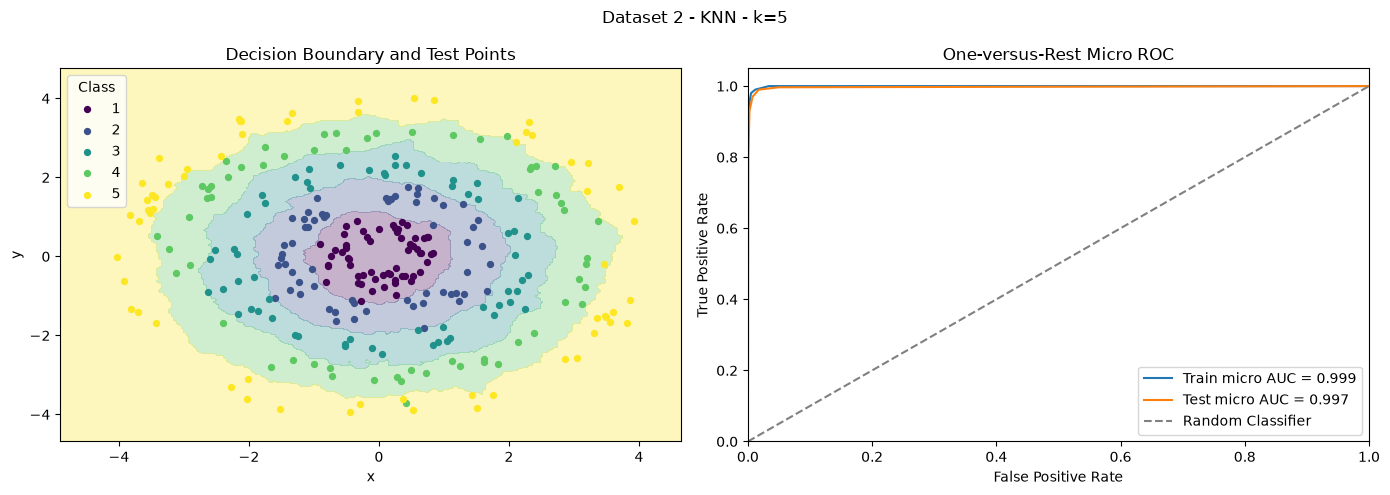

Dataset 2 | KNN - k=5 | Train Micro AUC: 0.9995 | Test Micro AUC: 0.9970


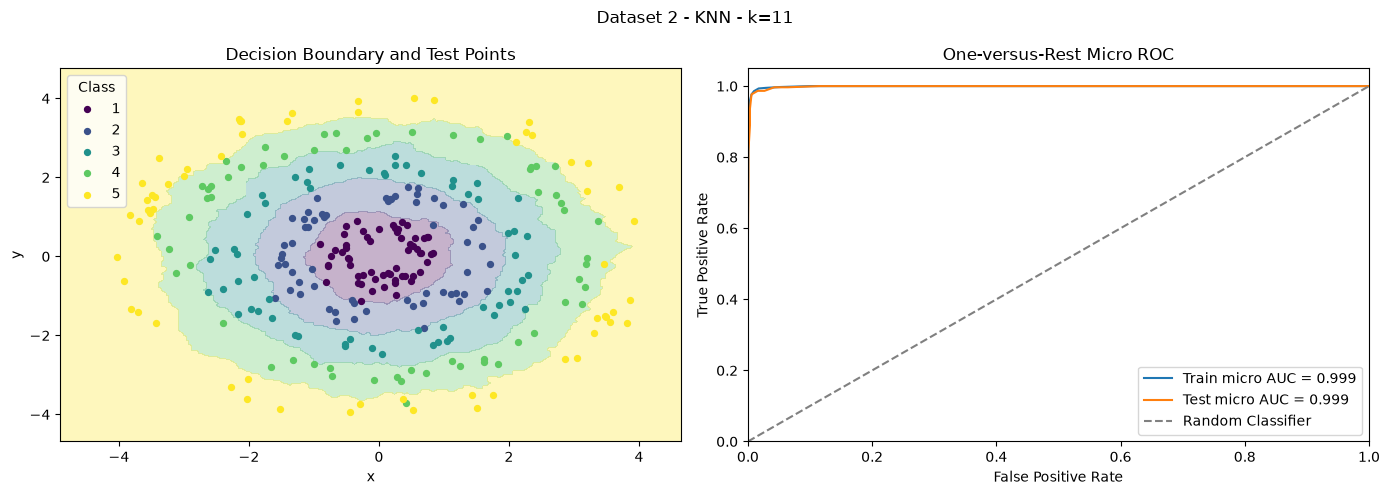

Dataset 2 | KNN - k=11 | Train Micro AUC: 0.9991 | Test Micro AUC: 0.9986


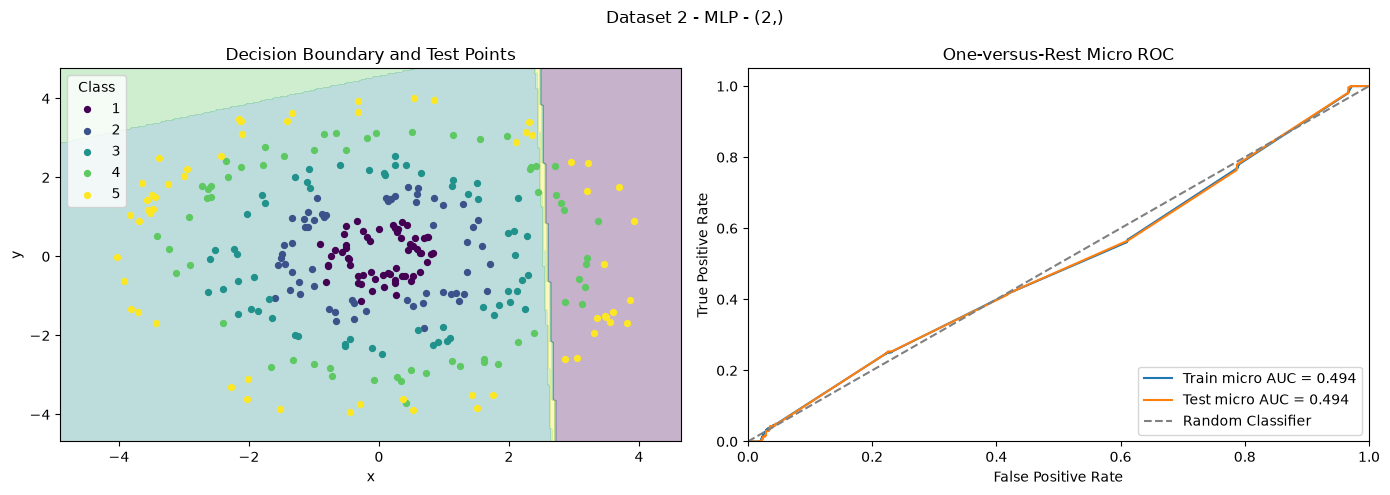

Dataset 2 | MLP - (2,) | Train Micro AUC: 0.4944 | Test Micro AUC: 0.4943


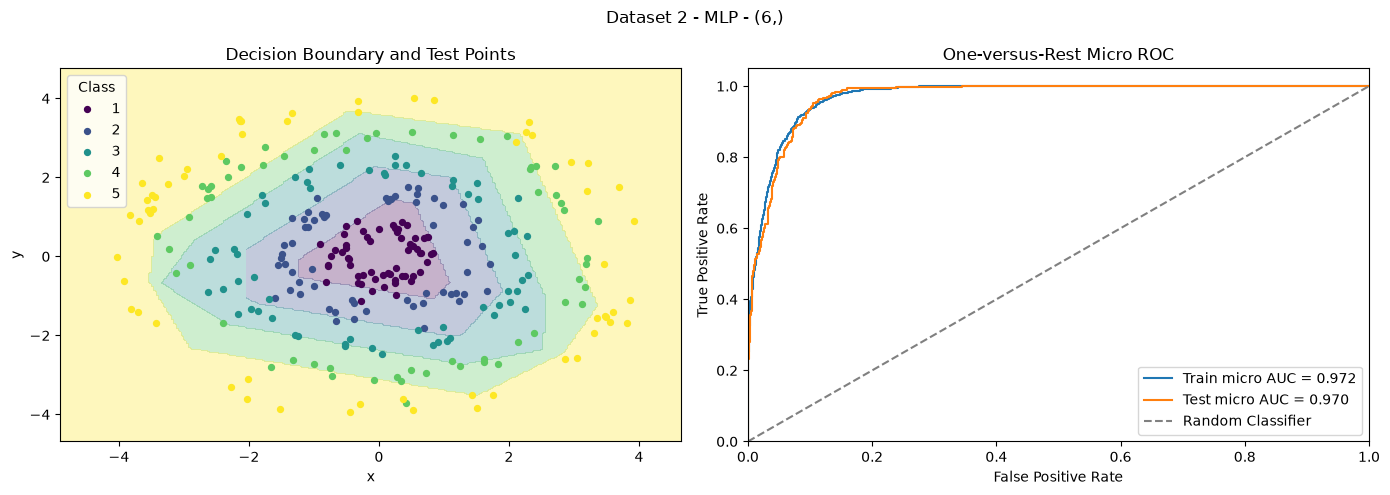

Dataset 2 | MLP - (6,) | Train Micro AUC: 0.9717 | Test Micro AUC: 0.9695


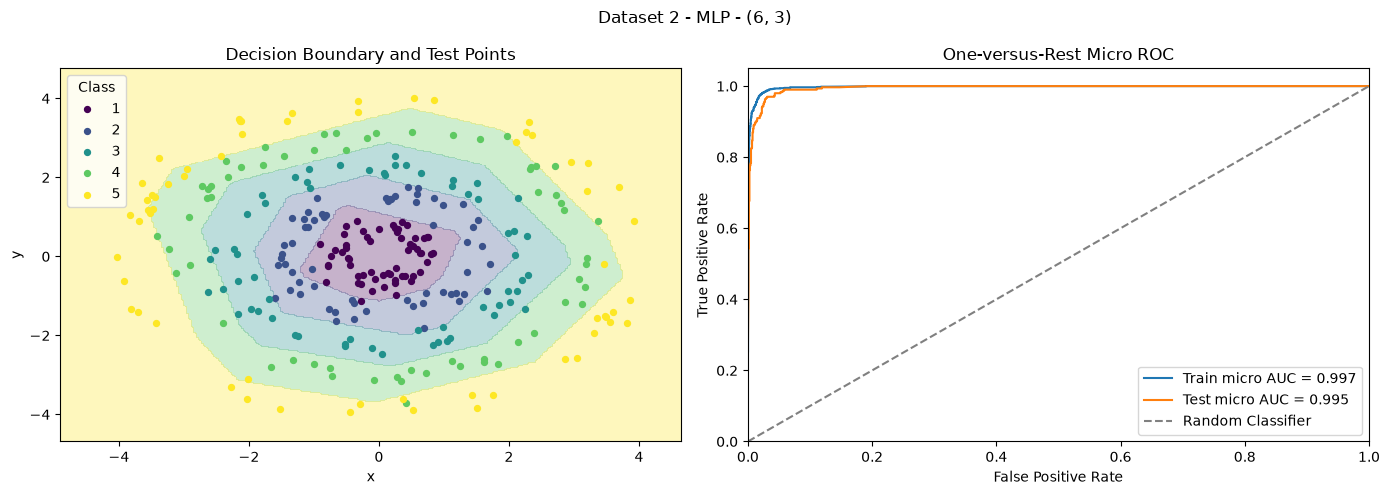

Dataset 2 | MLP - (6, 3) | Train Micro AUC: 0.9974 | Test Micro AUC: 0.9946


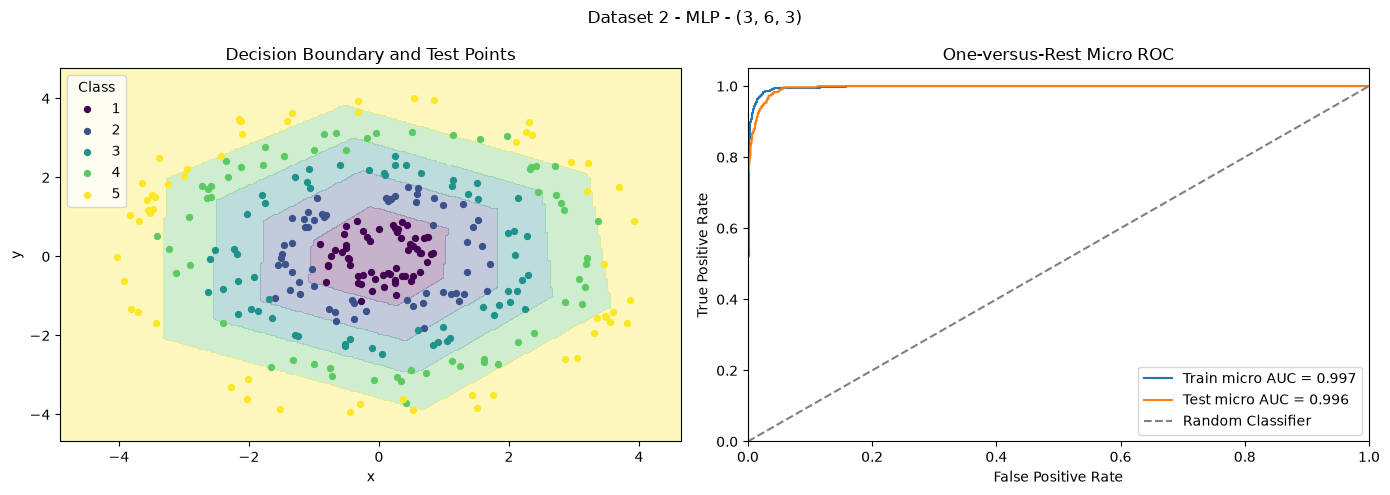

Dataset 2 | MLP - (3, 6, 3) | Train Micro AUC: 0.9971 | Test Micro AUC: 0.9959


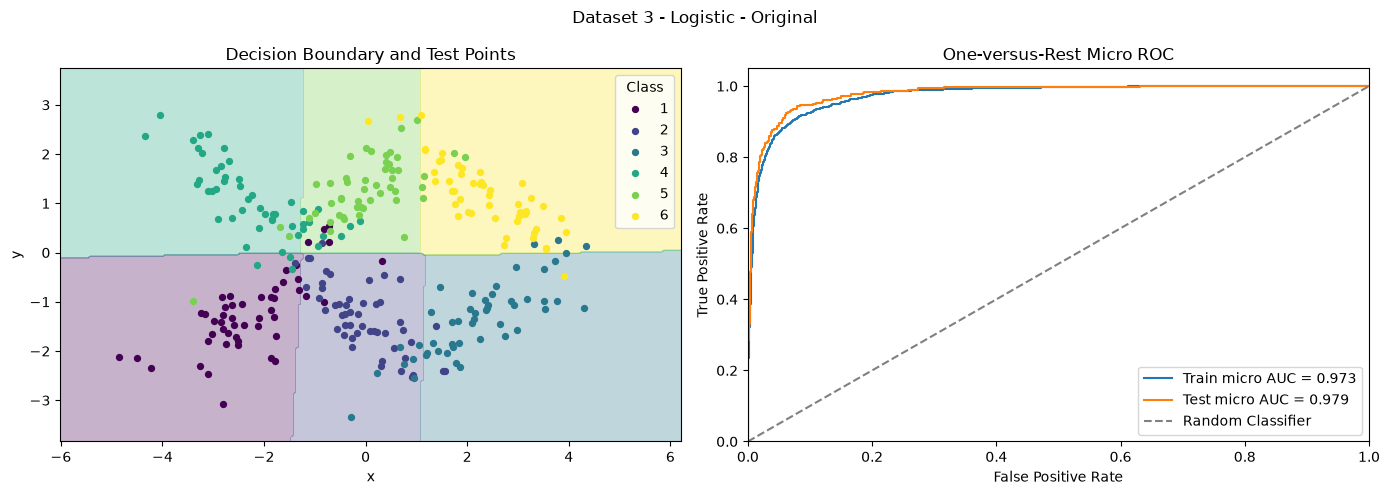

Dataset 3 | Logistic - Original | Train Micro AUC: 0.9735 | Test Micro AUC: 0.9790


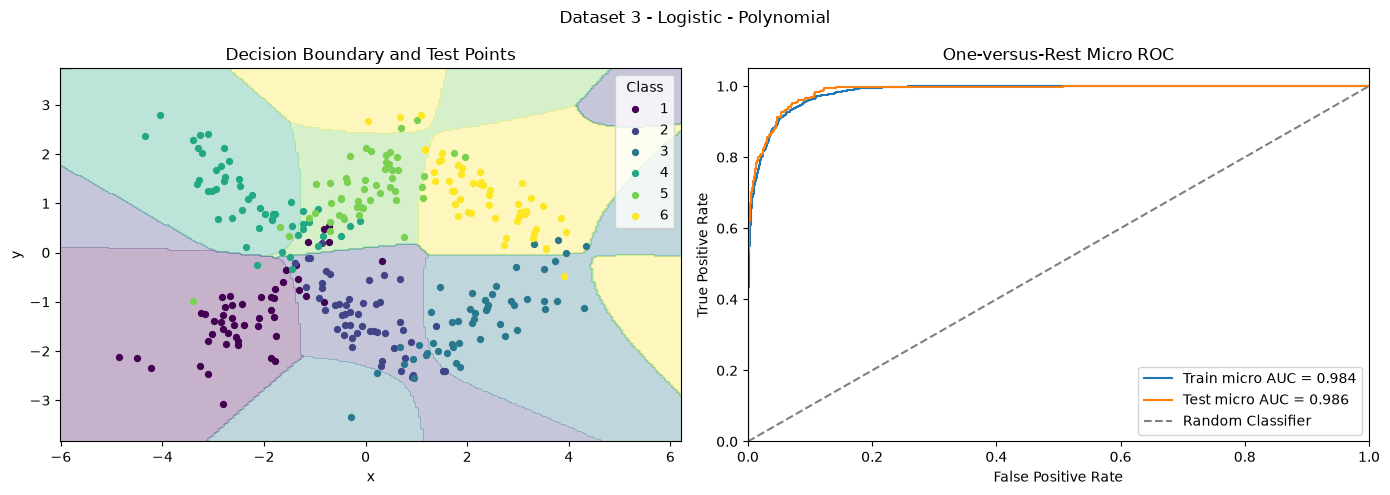

Dataset 3 | Logistic - Polynomial | Train Micro AUC: 0.9840 | Test Micro AUC: 0.9855


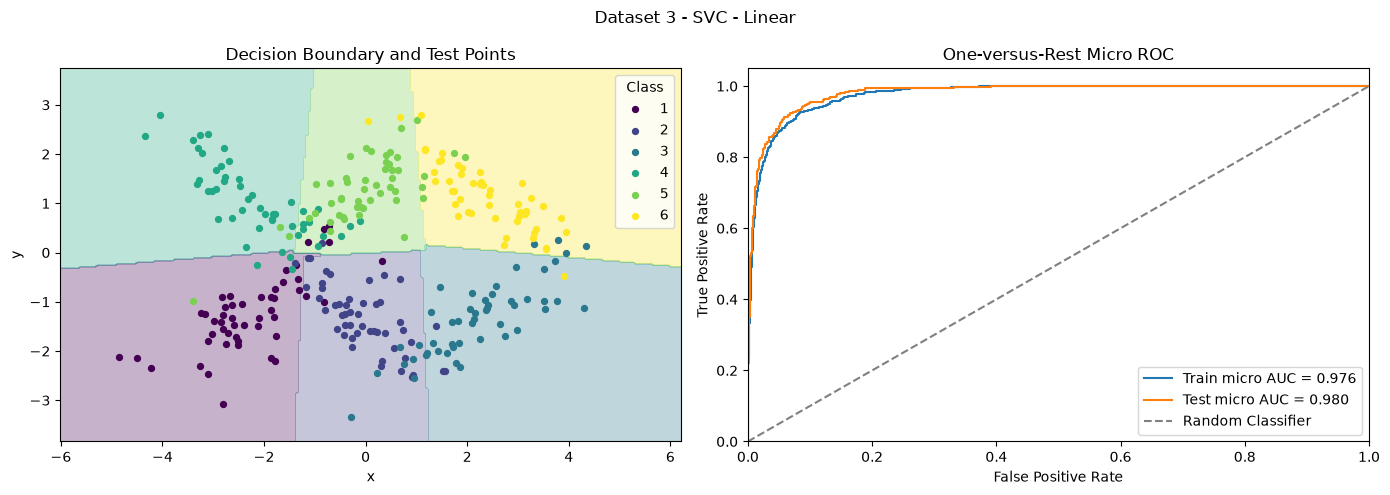

Dataset 3 | SVC - Linear | Train Micro AUC: 0.9761 | Test Micro AUC: 0.9803


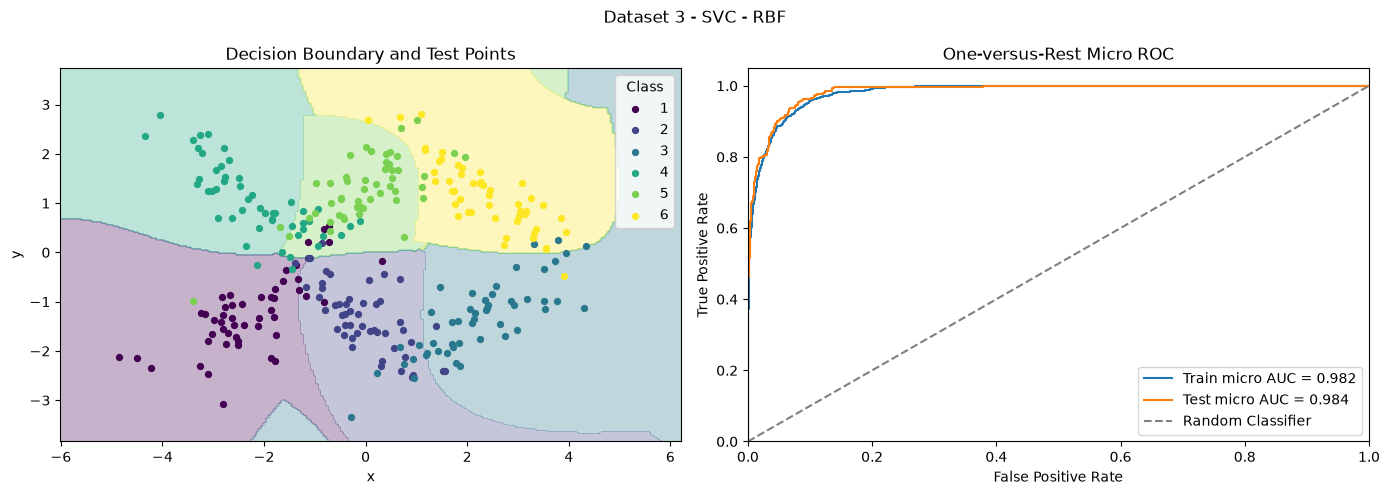

Dataset 3 | SVC - RBF | Train Micro AUC: 0.9815 | Test Micro AUC: 0.9843


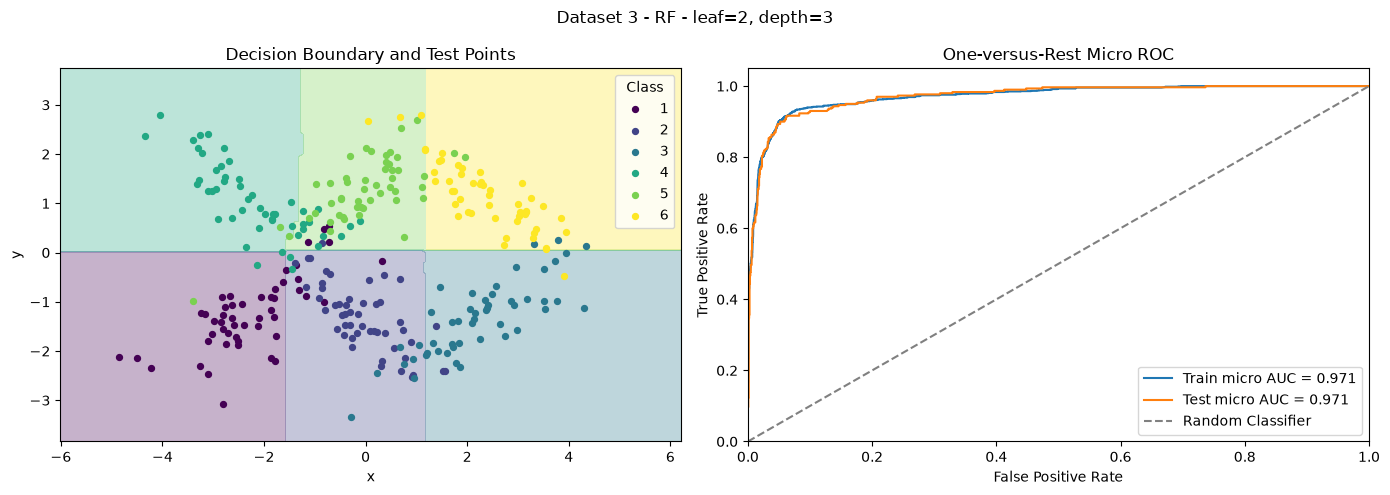

Dataset 3 | RF - leaf=2, depth=3 | Train Micro AUC: 0.9708 | Test Micro AUC: 0.9707


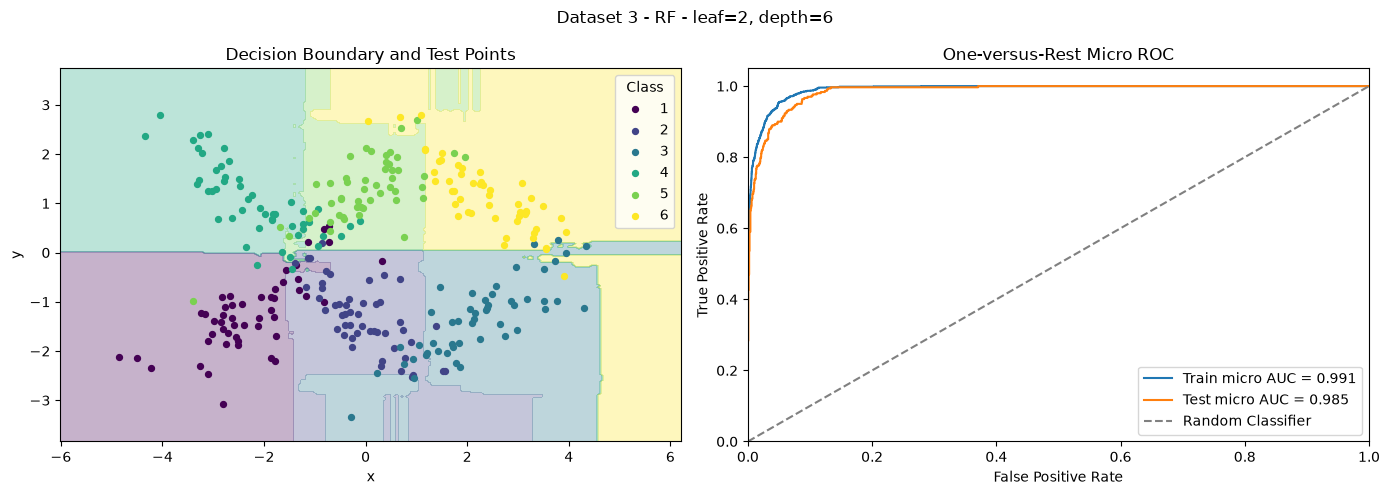

Dataset 3 | RF - leaf=2, depth=6 | Train Micro AUC: 0.9910 | Test Micro AUC: 0.9852


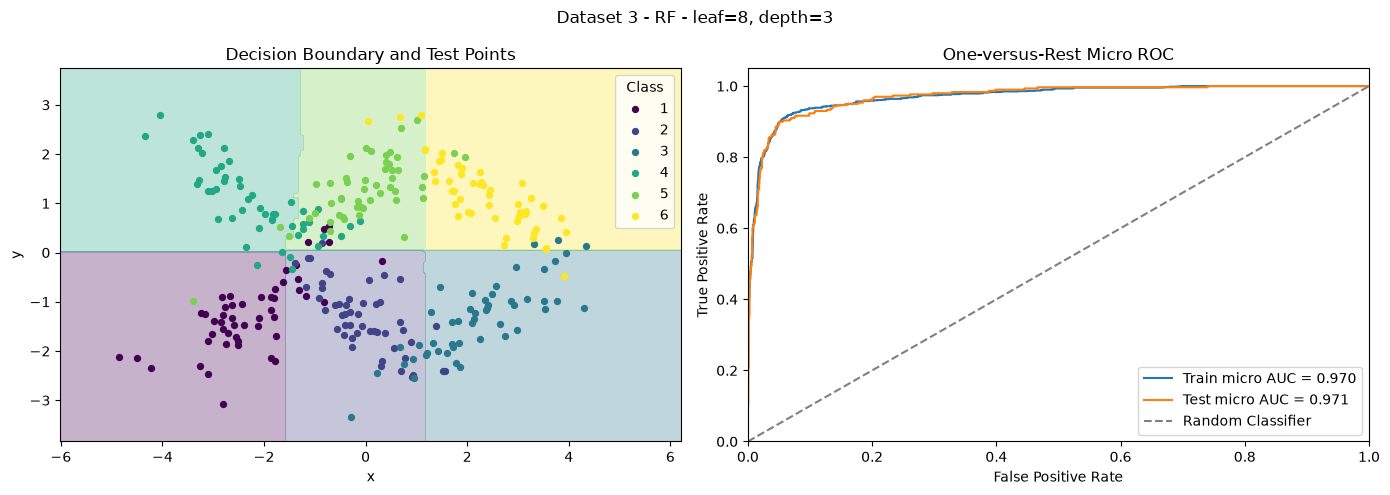

Dataset 3 | RF - leaf=8, depth=3 | Train Micro AUC: 0.9704 | Test Micro AUC: 0.9706


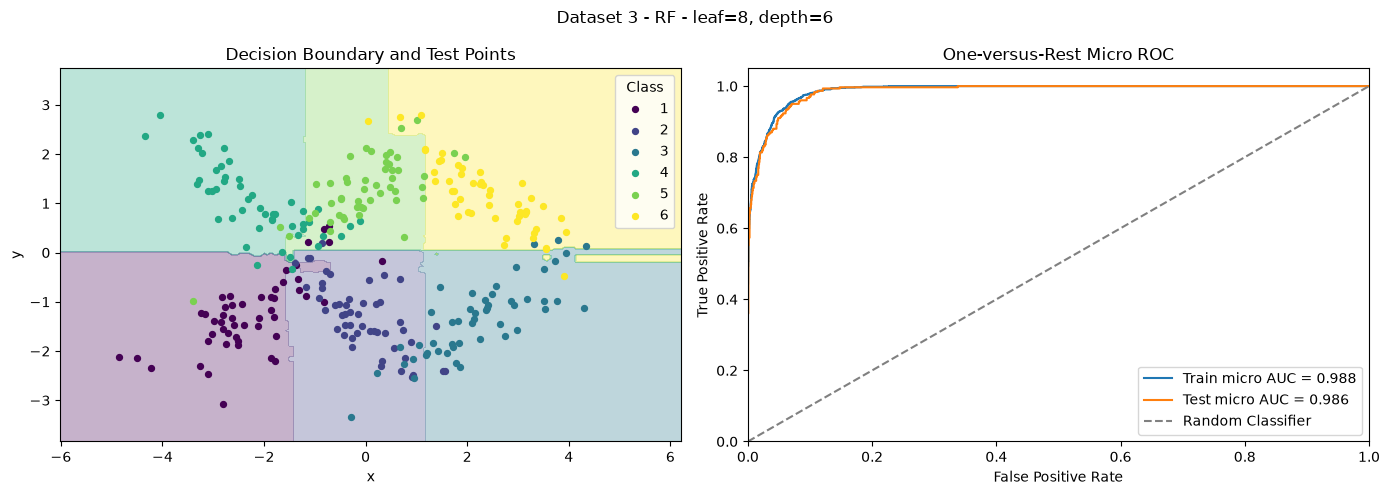

Dataset 3 | RF - leaf=8, depth=6 | Train Micro AUC: 0.9877 | Test Micro AUC: 0.9859


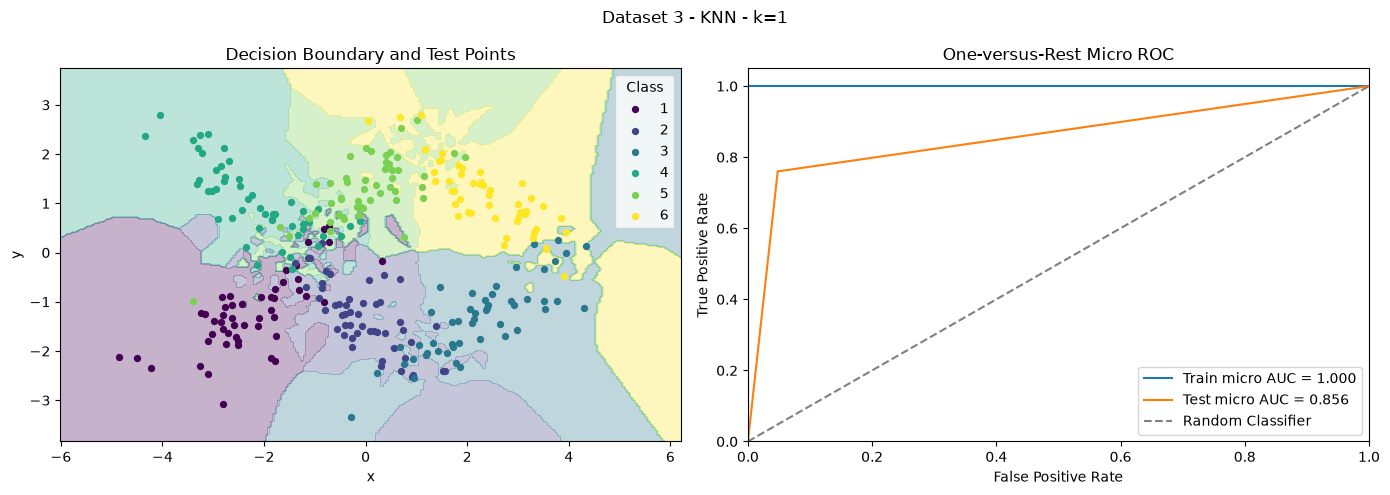

Dataset 3 | KNN - k=1 | Train Micro AUC: 1.0000 | Test Micro AUC: 0.8560


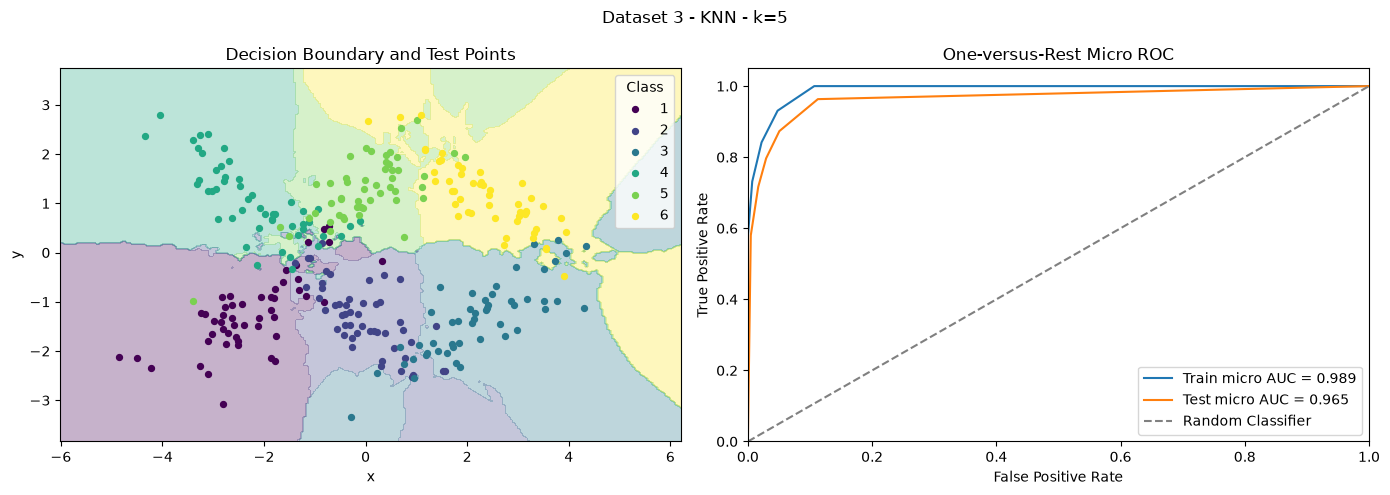

Dataset 3 | KNN - k=5 | Train Micro AUC: 0.9894 | Test Micro AUC: 0.9645


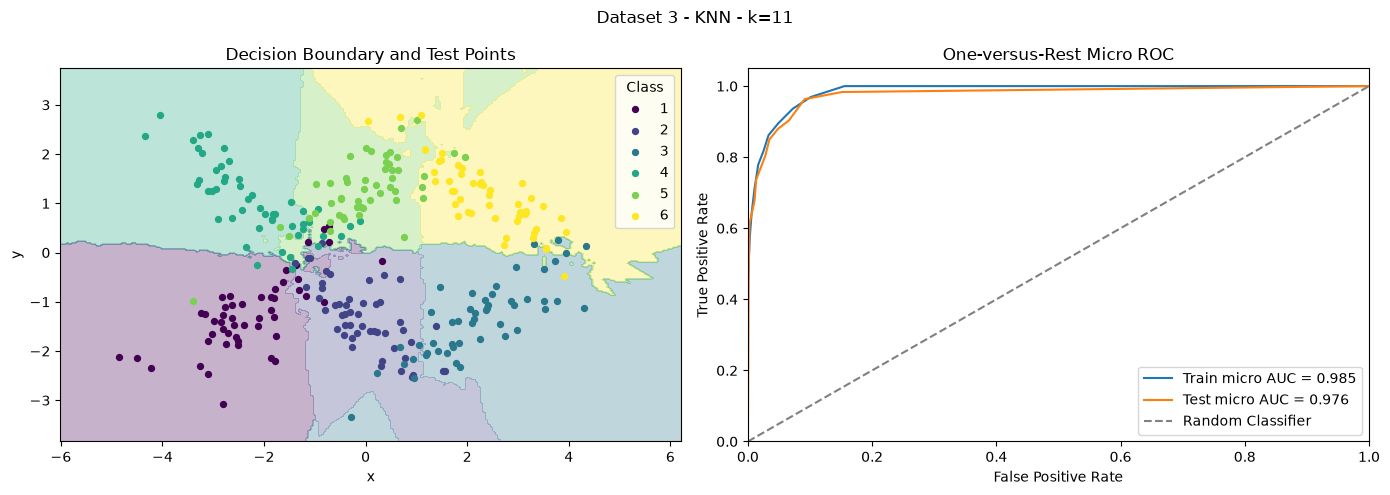

Dataset 3 | KNN - k=11 | Train Micro AUC: 0.9852 | Test Micro AUC: 0.9761


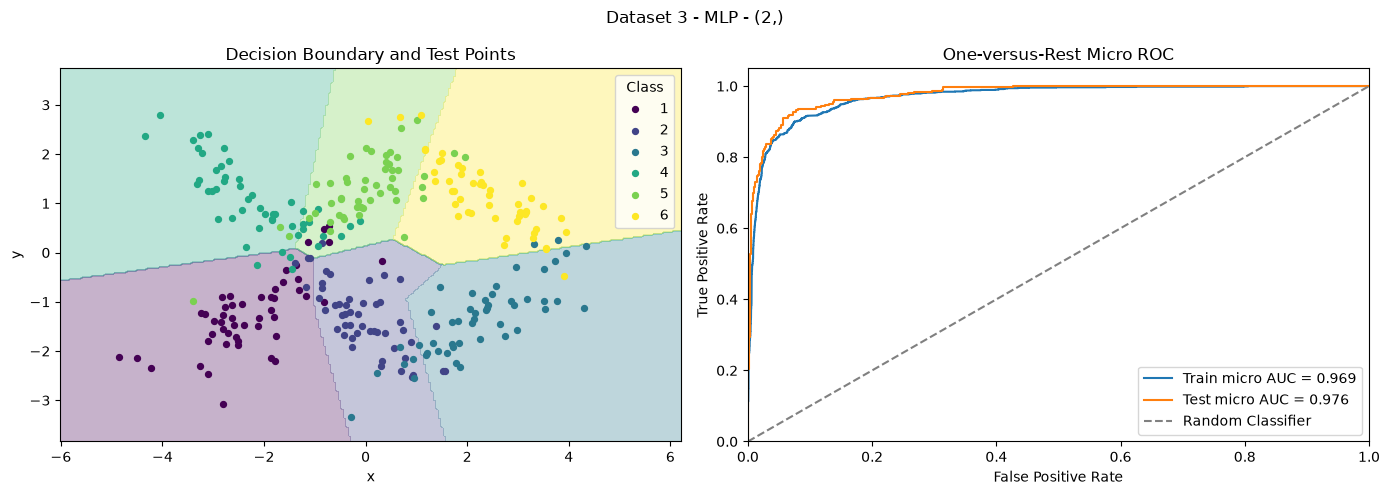

Dataset 3 | MLP - (2,) | Train Micro AUC: 0.9689 | Test Micro AUC: 0.9764


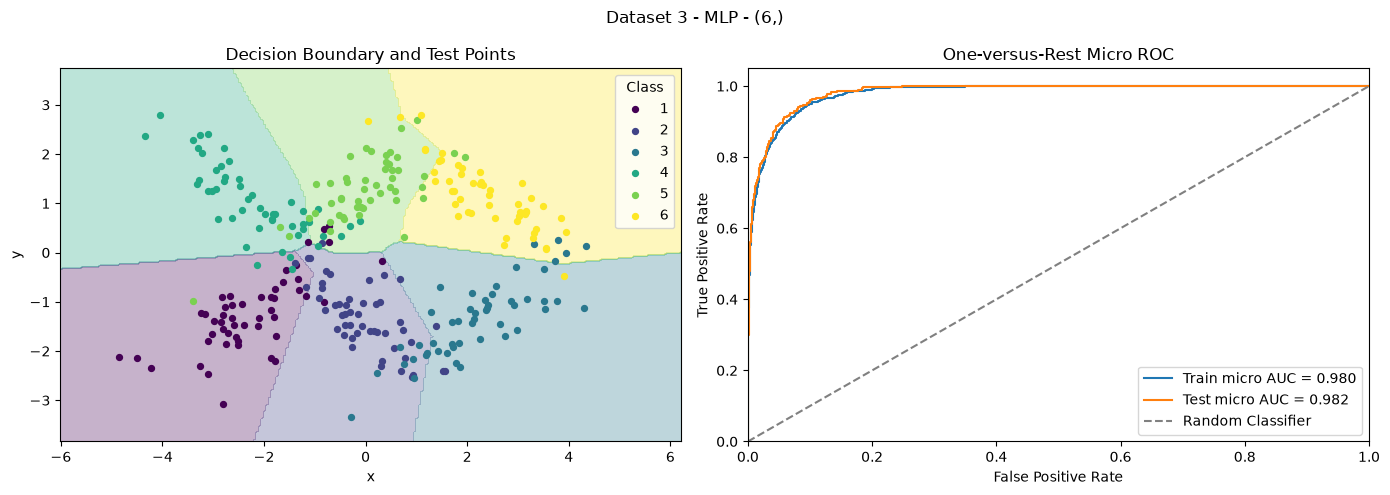

Dataset 3 | MLP - (6,) | Train Micro AUC: 0.9798 | Test Micro AUC: 0.9824


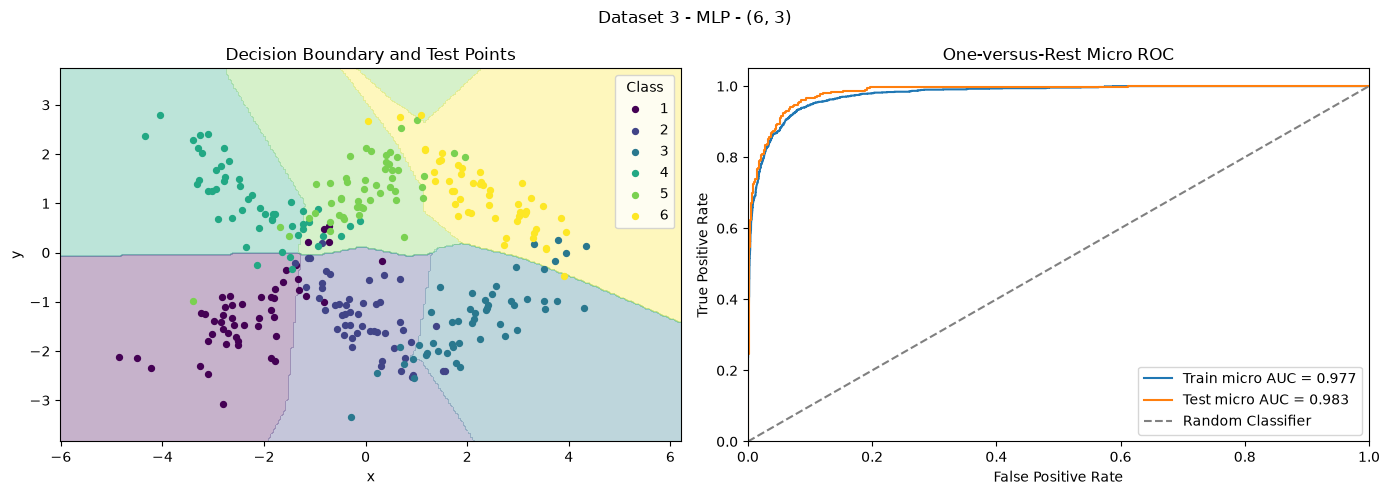

Dataset 3 | MLP - (6, 3) | Train Micro AUC: 0.9774 | Test Micro AUC: 0.9830


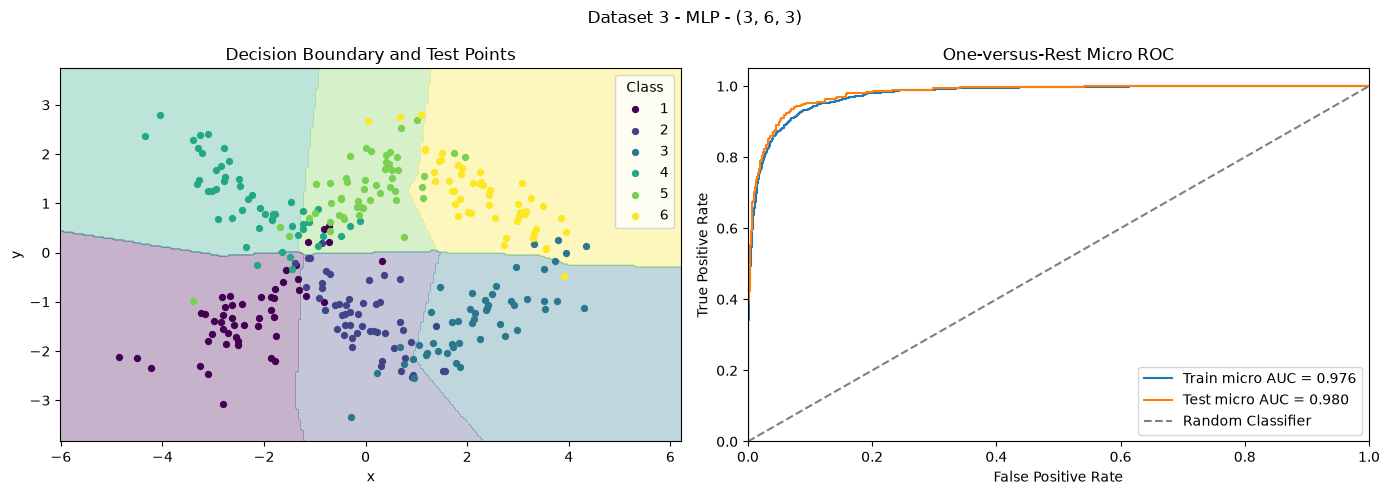

Dataset 3 | MLP - (3, 6, 3) | Train Micro AUC: 0.9763 | Test Micro AUC: 0.9799


In [18]:

# Decision boundaries and micro ROC curves

def plot_model_outputs(model, X_train, y_train, X_test, y_test,
                       dataset_name, model_name):

    classes = model.classes_
    n_classes = len(classes)

    # Predict probabilities.
    # Pipeline automatically handles polynomial transformation.
    train_prob = model.predict_proba(X_train)
    test_prob = model.predict_proba(X_test)

    # ---------------------------------------
    # Decision-boundary grid
    # ---------------------------------------

    x_min = min(X_train["x"].min(), X_test["x"].min()) - 0.5
    x_max = max(X_train["x"].max(), X_test["x"].max()) + 0.5

    y_min = min(X_train["y"].min(), X_test["y"].min()) - 0.5
    y_max = max(X_train["y"].max(), X_test["y"].max()) + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = pd.DataFrame({
        "x": xx.ravel(),
        "y": yy.ravel()
    })

    # Pipeline automatically transforms the grid when necessary.
    predictions = model.predict(grid)

    class_to_number = {
        label: j for j, label in enumerate(classes)
    }

    Z = np.array([
        class_to_number[label] for label in predictions
    ]).reshape(xx.shape)

    cmap = ListedColormap(
        plt.get_cmap("viridis", n_classes)(
            np.arange(n_classes)
        )
    )

    # ---------------------------------------
    # Create plots
    # ---------------------------------------

    fig, (ax1, ax2) = plt.subplots(
        1, 2, figsize=(14, 5)
    )

    # ---------------------------------------
    # Decision boundary and test observations
    # ---------------------------------------

    ax1.contourf(
        xx, yy, Z,
        levels=np.arange(n_classes + 1) - 0.5,
        cmap=cmap,
        alpha=0.3
    )

    for j, label in enumerate(classes):

        mask = y_test.to_numpy() == label

        ax1.scatter(
            X_test.loc[mask, "x"],
            X_test.loc[mask, "y"],
            color=cmap(j),
            label=str(label),
            s=18
        )

    ax1.set_xlabel("x")
    ax1.set_ylabel("y")
    ax1.set_title("Decision Boundary and Test Points")
    ax1.legend(title="Class")

    # ---------------------------------------
    # One-versus-rest micro ROC
    # ---------------------------------------

    y_train_bin = label_binarize(
        y_train, classes=classes
    )

    y_test_bin = label_binarize(
        y_test, classes=classes
    )

    # Pool all class indicators and probabilities.
    train_fpr, train_tpr, _ = roc_curve(
        y_train_bin.ravel(),
        train_prob.ravel()
    )

    test_fpr, test_tpr, _ = roc_curve(
        y_test_bin.ravel(),
        test_prob.ravel()
    )

    # Calculate micro AUC directly.
    train_auc = roc_auc_score(
        y_train_bin.ravel(),
        train_prob.ravel()
    )

    test_auc = roc_auc_score(
        y_test_bin.ravel(),
        test_prob.ravel()
    )

    ax2.plot(
        train_fpr, train_tpr,
        label=f"Train micro AUC = {train_auc:.3f}"
    )

    ax2.plot(
        test_fpr, test_tpr,
        label=f"Test micro AUC = {test_auc:.3f}"
    )

    # Diagonal reference line.
    ax2.plot(
        [0, 1], [0, 1],
        "--", color="gray",
        label="Random Classifier"
    )

    ax2.set_xlabel("False Positive Rate")
    ax2.set_ylabel("True Positive Rate")
    ax2.set_title("One-versus-Rest Micro ROC")

    ax2.legend(loc="lower right")
    ax2.set_xlim(0, 1)
    ax2.set_ylim(0, 1.05)

    fig.suptitle(
        f"{dataset_name} - {model_name}"
    )

    plt.tight_layout()
    plt.show()

    return train_auc, test_auc


# ---------------------------------------
# Plot all models across all datasets
# ---------------------------------------

for i, (X_train, X_test, y_train, y_test) in enumerate(
    split_data, start=1
):

    dataset_name = f"Dataset {i}"

    for model_name, model in models[dataset_name].items():

        train_auc, test_auc = plot_model_outputs(
            model,
            X_train,
            y_train,
            X_test,
            y_test,
            dataset_name,
            model_name
        )

        print(
            f"{dataset_name} | {model_name} | "
            f"Train Micro AUC: {train_auc:.4f} | "
            f"Test Micro AUC: {test_auc:.4f}"
        )
